# Project 2: SNLI with GloVe and LSTM encoders

Compare **LogReg, MLP1 and MLP2** using mean-pooled **100d/300d GloVe**, then
compare pooling with a **frozen-embedding LSTM**. Use two shared five-fold grouped CV runs,
tune the strongest pooled and recurrent designs on official validation, and
evaluate the two selected models on official test.

Follow the [design notes](project2.md) and [tutorial](tutorial.ipynb). Each section
contains its own experiment and plots. Results are saved as ordinary pickle
files in `part2/RESULTS`; figures are exported as PNG/PDF. Run All trains fresh
models. The notebook is supplied unexecuted for the external runner.

## 1. Settings

Use one fixed sample targeting **60,000 labelled pairs**, keeping whole premise
groups. Run **five grouped folds for seeds 0 and 3**, using the matching seed
for model initialization and batch shuffling. Sampling, pilot, dev tuning and
final refits keep seed 0. Official dev and test stay separate. Models share
fitting rows within each seed/fold; final fits use the full fixed sample.

Pool tokenization lowercases and removes punctuation and stopwords. LSTM
retains punctuation and stopwords. Both concatenate separate premise and
hypothesis representations. Select one winner per encoder family for dev tuning.
Two CV repetitions provide a limited check of seed sensitivity.

In [1]:
from collections import Counter
from itertools import chain, combinations, product
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile
import pickle
import random
import shutil
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import t
import nltk
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from datasets import DatasetDict, load_dataset, load_from_disk
from IPython.display import display
from tqdm.auto import tqdm

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'part2/clslib.py').exists())
sys.path.insert(0, str(ROOT))
from part2 import clslib, analysis

### Configuration

Use batch size 64, the tutorial's [50] / [50, 50] MLP layers, and frozen GloVe.
Keep the 60k sample, CV seeds [0, 3] and 5–10 epoch range in `BASE`. Save measurements
as pickle files and figures as PNG/PDF. Results can vary across hardware.

In [2]:
RESULTS = Path('/scratch-shared/scur0565/project2/RESULTS')
FIGURES = Path('/scratch-shared/scur0565/project2/figures')
ASSETS = Path('/scratch-shared/scur0565/project2/glove')
LABELS = ['entailment', 'neutral', 'contradiction']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BASE = {
    'revision': 'cdb5c3d5eed6ead6e5a341c8e56e669bb666725b',
    'training_rows': 60000, 'sampling_seed': 0,
    'cv_seeds': [0, 3], 'n_splits': 5, 'model_seed': 0,
    'embedding_dims': [100, 300], 'batch_size': 64,
    'learning_rate': .001, 'weight_decay': .0001, 'dropout': .1,
    'hidden_dims': {'logreg': [], 'mlp1': [50], 'mlp2': [50, 50]},
    'lstm_hidden': 300, 'min_epochs': 5, 'max_epochs': 10,
    'tune_dropout': [.1, .15, .2], 'tune_learning_rate': [.1, .2, .3],
    'tune_hidden': [100, 300, 500], 'rope': .005,
    'analysis_rows': 1200, 'sibling_threshold': .9,
    'mcmc_warmup': 1000, 'mcmc_samples': 1000, 'mcmc_chains': 2,
}
for directory in [RESULTS, FIGURES, ASSETS]:
    directory.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_result(name, value):
    path = RESULTS / f'{name}.pkl'
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('wb') as handle:
        pickle.dump(value, handle, protocol=pickle.HIGHEST_PROTOCOL)


def save_figure(figure, name):
    for extension in ['png', 'pdf']:
        figure.savefig(FIGURES / f'{name}.{extension}', dpi=180, bbox_inches='tight')


set_seed(BASE['model_seed'])
for package in ['punkt_tab', 'stopwords', 'opinion_lexicon']:
    nltk.download(package, quiet=True)
save_result('settings', {'config': BASE, 'python': sys.version, 'device': str(DEVICE)})
print('Device:', DEVICE)
display(pd.Series(BASE, name='value').to_frame())

Device: cuda


,value
revision,cdb5c3d5eed6ead6e5a341c8e56e669bb666725b
training_rows,60000
sampling_seed,0
cv_seeds,"[0, 3]"
n_splits,5
model_seed,0
embedding_dims,"[100, 300]"
batch_size,64
learning_rate,0.001
weight_decay,0.0001


## 2. Data and folds

Load pinned SNLI, removing invalid labels and blank texts. Exclude exact
validation/test premise overlaps from training and test overlaps from dev.
Sample whole premise groups and keep them together in CV. Save the actual
rows and assignments; keeping the last group whole can exceed the sample target.

In [3]:
def load_snli():
    directory = ROOT / 'part1/data/snli' / BASE['revision'] / 'cleaned-v1'
    if directory.exists():
        return load_from_disk(str(directory))
    raw = load_dataset('stanfordnlp/snli', revision=BASE['revision'],
                       cache_dir='/scratch-shared/scur0565/project2/huggingface')
    cleaned = {}
    for split, rows in raw.items():
        rows = rows.map(lambda row, i: {'example_id': f'{split}:{i}'}, with_indices=True)
        cleaned[split] = rows.filter(lambda r: r['label'] in [0, 1, 2]
            and all(isinstance(r[k], str) and r[k].strip() for k in ['premise', 'hypothesis']))
    return DatasetDict(cleaned)


def sample_groups(frame, target_rows, seed):
    if not 1 <= target_rows <= len(frame):
        raise ValueError('Sample target must lie within the data.')
    sizes = frame.groupby('premise', sort=True).size()
    shuffled = sizes.iloc[np.random.default_rng(seed).permutation(len(sizes))]
    count = np.searchsorted(shuffled.cumsum(), target_rows) + 1
    return frame.loc[frame.premise.isin(shuffled.index[:count])].reset_index(drop=True)


data = load_snli()
assert all(data[s].features['label'].names == LABELS for s in data)
columns = ['example_id', 'premise', 'hypothesis', 'label']
frames = {s: data[s].select_columns(columns).to_pandas() for s in data}
test = frames['test']
dev = frames['validation'].loc[~frames['validation'].premise.isin(test.premise)].reset_index(drop=True)
heldout_premises = set(frames['validation'].premise) | set(test.premise)
eligible = frames['train'].loc[~frames['train'].premise.isin(heldout_premises)]
train = sample_groups(eligible, BASE['training_rows'], BASE['sampling_seed'])
for a, b in combinations([train, dev, test], 2):
    assert set(a.premise).isdisjoint(b.premise)
    assert set(a.example_id).isdisjoint(b.example_id)

assignments = train[['example_id', 'premise', 'label']].copy()
for seed in BASE['cv_seeds']:
    splitter = StratifiedGroupKFold(n_splits=BASE['n_splits'], shuffle=True, random_state=seed)
    for fold, (fitting, heldout) in enumerate(splitter.split(train, train.label, train.premise)):
        assert set(train.iloc[fitting].premise).isdisjoint(train.iloc[heldout].premise)
        assignments.loc[heldout, f'seed_{seed}'] = fold
    assignments[f'seed_{seed}'] = assignments[f'seed_{seed}'].astype(int)
save_result('data_and_folds', {'train': train, 'dev': dev, 'test': test, 'folds': assignments})
display(pd.DataFrame([{'split': s, 'rows': len(f), 'premises': f.premise.nunique()}
                     for s, f in [('train', train), ('dev', dev), ('test', test)]]))

Using the latest cached version of the dataset since stanfordnlp/snli couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at /scratch-shared/scur0565/project2/huggingface/stanfordnlp___snli/plain_text/0.0.0/cdb5c3d5eed6ead6e5a341c8e56e669bb666725b (last modified on Sat Nov 21 09:44:39 2026).


,split,rows,premises
0,train,60000,16450
1,dev,9839,3318
2,test,9824,3323


### Sentence lengths and labels

Compare training and dev word-length distributions and label proportions.
Lengths count whitespace words before tokenization. Normalized plots allow
comparison of splits with different sizes.

count  mean  std  min  25%   50%   75%   max
split role                                                      
dev   hypothesis   9839.0   7.5  3.1  2.0  5.0   7.0   9.0  48.0
      premise      9839.0  13.9  6.3  2.0  9.0  13.0  18.0  50.0
train hypothesis  60000.0   7.4  3.1  1.0  5.0   7.0   9.0  38.0
      premise     60000.0  12.9  5.5  2.0  9.0  12.0  16.0  53.0

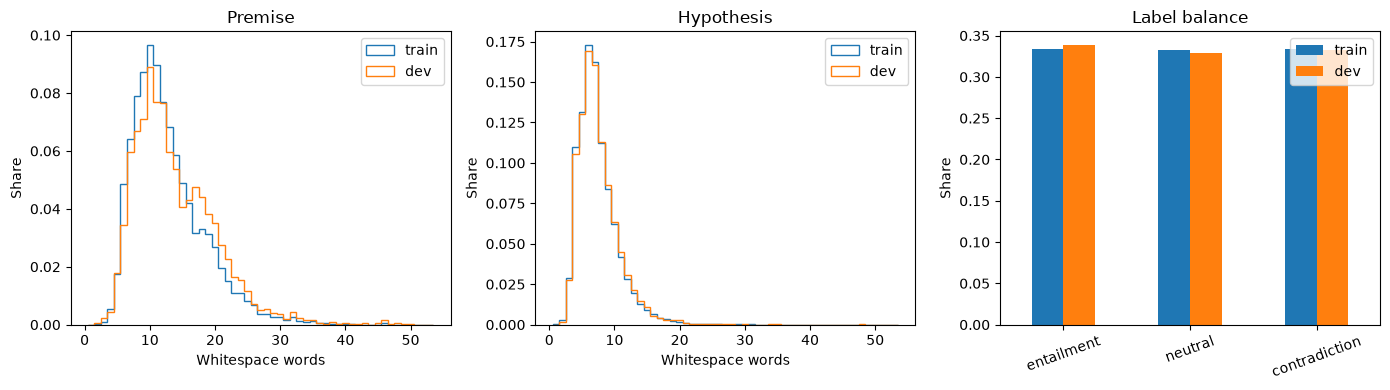

In [4]:
lengths = pd.concat([pd.DataFrame({'split': split, 'role': role,
    'words': frame[role].str.split().str.len()})
    for split, frame in [('train', train), ('dev', dev)] for role in ['premise', 'hypothesis']])
display(lengths.groupby(['split', 'role']).words.describe().round(1))
save_result('sentence_lengths', lengths)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, role in zip(axes[:2], ['premise', 'hypothesis']):
    for split in ['train', 'dev']:
        values = lengths.loc[lengths.role.eq(role) & lengths.split.eq(split), 'words']
        ax.hist(values, bins=np.arange(.5, lengths.words.max()+1.5), density=True,
                histtype='step', label=split)
    ax.set(title=role.capitalize(), xlabel='Whitespace words', ylabel='Share')
    ax.legend()
shares = pd.DataFrame({s: f.label.value_counts(normalize=True).reindex(range(3))
                       for s, f in [('train', train), ('dev', dev)]})
shares.index = LABELS
shares.plot.bar(ax=axes[2], rot=20, title='Label balance', ylabel='Share')
fig.tight_layout()
save_figure(fig, 'data_lengths_and_balance')
plt.show()

## 3. GloVe and tokenization

Use 100d and 300d English GloVe vectors from the same 6B release. Place the
text files in `part2/data/glove`, or let this cell download them. The course
loader supplies zero PAD and mean UNK vectors.

Tokenize with NLTK `BasicTokenizer`. Its segmentation need not match GloVe's
exactly: check coverage below. Removing stopwords can also remove negation.

In [5]:
files = {d: ASSETS / f'glove.6B.{d}d.txt' for d in BASE['embedding_dims']}
if not all(path.exists() for path in files.values()):
    archive = ASSETS / 'glove.6B.zip'
    if not archive.exists():
        temporary = ASSETS / 'glove.6B.download'
        with urlopen('https://nlp.stanford.edu/data/glove.6B.zip', timeout=300) as source:
            with temporary.open('wb') as output:
                shutil.copyfileobj(source, output)
        temporary.replace(archive)
    with ZipFile(archive) as zipped:
        for dim, path in files.items():
            if not path.exists():
                with zipped.open(path.name) as source, path.open('wb') as output:
                    shutil.copyfileobj(source, output)

embeddings = {}
for dim, path in files.items():
    embeddings[dim] = clslib.PretrainedEmbeddings(str(path), dim)
    save_result(f'glove_{dim}', embeddings[dim])
TOKENIZERS = {
    'pool': clslib.BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True),
    'lstm': clslib.BasicTokenizer(lowercase=True, remove_punct=False, remove_stopwords=False),
}


def tokenize_pairs(frame, mode):
    tokenizer = TOKENIZERS[mode]
    return {role: [tokenizer.tokens(text) for text in frame[role]]
            for role in ['premise', 'hypothesis']}


tokens = {(split, mode): tokenize_pairs(frame, mode)
          for split, frame in [('train', train), ('dev', dev)] for mode in TOKENIZERS}
save_result('train_dev_tokens', tokens)
example = "A man isn't running and nobody is asleep."
display(pd.DataFrame({'mode': list(TOKENIZERS),
                     'tokens': [t.tokens(example) for t in TOKENIZERS.values()]}))

,mode,tokens
0,pool,"[man, running, nobody, asleep]"
1,lstm,"[a, man, is, n't, running, and, nobody, is, as..."


### Vocabulary coverage

Report token/type coverage, OOV counts and empty sentences for each tokenizer,
sentence role and split. Inspect OOV examples separately. High coverage means
words have vectors; it does not establish good inference representations.

,split,mode,role,dim,tokens,types,oov_tokens,oov_types,token_coverage,type_coverage,empty_sentences
0,train,pool,premise,100,443346,7665,605,142,99.86%,98.15%,0
1,train,pool,hypothesis,100,241268,11720,953,780,99.61%,93.34%,1
2,train,pool,premise,300,443346,7665,605,142,99.86%,98.15%,0
3,train,pool,hypothesis,300,241268,11720,953,780,99.61%,93.34%,1
4,train,lstm,premise,100,841915,8075,1664,328,99.80%,95.94%,0
5,train,lstm,hypothesis,100,494501,12135,1151,933,99.77%,92.31%,0
6,train,lstm,premise,300,841915,8075,1664,328,99.80%,95.94%,0
7,train,lstm,hypothesis,300,494501,12135,1151,933,99.77%,92.31%,0
8,dev,pool,premise,100,78885,3958,108,35,99.86%,99.12%,0
9,dev,pool,hypothesis,100,40142,4868,134,124,99.67%,97.45%,0


,split,mode,role,dim,top_oov
0,train,pool,premise,100,"[(sunhat, 21), (backdropped, 18), (rollerskate..."
1,train,pool,hypothesis,100,"[(selfie, 8), (dirtbike, 7), (wakeboarder, 7),..."
2,train,pool,premise,300,"[(sunhat, 21), (backdropped, 18), (rollerskate..."
3,train,pool,hypothesis,300,"[(selfie, 8), (dirtbike, 7), (wakeboarder, 7),..."
4,train,lstm,premise,100,"[(blond-hair, 162), (red-hair, 63), (long-slee..."
5,train,lstm,hypothesis,100,"[(selfie, 8), (dirtbike, 7), (wakeboarder, 7),..."
6,train,lstm,premise,300,"[(blond-hair, 162), (red-hair, 63), (long-slee..."
7,train,lstm,hypothesis,300,"[(selfie, 8), (dirtbike, 7), (wakeboarder, 7),..."
8,dev,pool,premise,100,"[(floaties, 6), (rollerskater, 6), (backset, 3..."
9,dev,pool,hypothesis,100,"[(amusment, 3), (surfboarder, 3), (indain, 2),..."


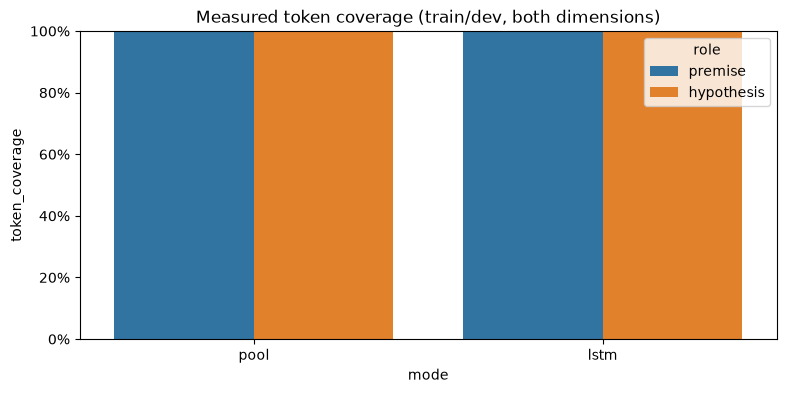

In [6]:
def coverage_table(split, mode, tokenized, emb):
    rows = []
    for role, sentences in tokenized.items():
        counts = Counter(chain.from_iterable(sentences))
        oov = {word: count for word, count in counts.items() if word not in emb}
        rows.append({'split': split, 'mode': mode, 'role': role, 'dim': emb.num_dims,
            'tokens': sum(counts.values()), 'types': len(counts),
            'oov_tokens': sum(oov.values()), 'oov_types': len(oov),
            'token_coverage': 1-sum(oov.values())/max(1, sum(counts.values())),
            'type_coverage': 1-len(oov)/max(1, len(counts)),
            'empty_sentences': sum(not s for s in sentences),
            'top_oov': sorted(oov.items(), key=lambda x: (-x[1], x[0]))[:15]})
    return rows


coverage = pd.DataFrame(list(chain.from_iterable(
    coverage_table(split, mode, ts, emb) for (split, mode), ts in tokens.items()
    for emb in embeddings.values())))
save_result('train_dev_coverage', coverage)
display(coverage.drop(columns='top_oov').style.format(
    {'token_coverage': '{:.2%}', 'type_coverage': '{:.2%}'}))
display(coverage[['split', 'mode', 'role', 'dim', 'top_oov']])
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=coverage, x='mode', y='token_coverage', hue='role', errorbar=None, ax=ax)
ax.set(ylim=(0, 1), title='Measured token coverage (train/dev, both dimensions)')
ax.yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, 'embedding_coverage')
plt.show()

## 4. Similarity and analogies

Probe the listed lexical relations using cosine, nearest neighbours and
`a − b + c` analogies. Exclude query words, PAD and UNK; flag missing words.
Word-level relations alone do not establish sentence entailment. Inspect
antonym similarity and gender analogies for limitations and possible bias.

In [2]:
def cosine(u, v):
    return float(np.dot(u, v)/max(float(np.linalg.norm(u)*np.linalg.norm(v)), 1e-12))


def topk(emb, query, k=5, exclude=()):
    if isinstance(query, str):
        if query not in emb:
            return []
        exclude = (*exclude, query)
        query = emb.embed_word(query)
    scores = emb.vectors @ query / np.maximum(np.linalg.norm(emb.vectors, axis=1)*np.linalg.norm(query), 1e-12)
    scores[[0, emb.vocab.default_index, *[emb.index(w) for w in exclude]]] = -np.inf
    ids = np.argsort(scores)[-k:][::-1]
    return [(emb.word(int(i)), float(scores[i])) for i in ids if np.isfinite(scores[i])]


RELATIONS = {
    'hypernymy': [('dog', 'animal'), ('car', 'vehicle')],
    'antonymy': [('hot', 'cold'), ('asleep', 'awake')],
    'co-hyponymy': [('dog', 'cat'), ('red', 'blue')],
    'synonymy': [('child', 'kid'), ('sofa', 'couch')],
    'meronymy': [('wheel', 'car'), ('hand', 'body')],
    'gender': [('man', 'woman'), ('king', 'queen')],
    'inflection': [('dog', 'dogs'), ('walk', 'walked')],
}
relation_rows, analogy_rows, neighbour_rows = [], [], []
for dim, emb in embeddings.items():
    for relation, pairs in RELATIONS.items():
        for a, b in pairs:
            known = a in emb and b in emb
            relation_rows.append({'dim': dim, 'relation': relation, 'a': a, 'b': b,
                'in_vocab': known, 'cosine': cosine(emb.embed_word(a), emb.embed_word(b)) if known else np.nan})
    for a, b, c, expected in [('king', 'man', 'woman', 'queen'), ('dogs', 'dog', 'cat', 'cats'),
                             ('walked', 'walk', 'talk', 'talked'), ('doctor', 'man', 'woman', None)]:
        answers = topk(emb, emb.embed_word(a)-emb.embed_word(b)+emb.embed_word(c), exclude=[a, b, c]) if all(w in emb for w in [a,b,c]) else []
        analogy_rows.append({'dim': dim, 'query': f'{a}-{b}+{c}', 'expected': expected, 'answers': answers})
    for word in ['not', 'no', 'person', 'king', 'nurse']:
        neighbour_rows.append({'dim': dim, 'word': word, 'neighbours': topk(emb, word)})
probes = {'relations': pd.DataFrame(relation_rows), 'analogies': pd.DataFrame(analogy_rows),
          'neighbours': pd.DataFrame(neighbour_rows)}
save_result('lexical_probes', probes)
for table in probes.values():
    display(table.round(3))

NameError: name 'embeddings' is not defined

In [4]:
import numpy as np

def round_cell(x, nd=4):
    if isinstance(x, (float, np.floating)):
        return round(float(x), nd)
    if isinstance(x, np.ndarray):
        return np.round(x, nd).tolist()
    if isinstance(x, (list, tuple)):
        return type(x)(round_cell(v, nd) for v in x)
    if isinstance(x, dict):
        return {k: round_cell(v, nd) for k, v in x.items()}
    return x

for name, table in probes.items():
    print(f'Lexical probe: {name} ({len(table)} rows)')
    display(table.map(round_cell).style.hide(axis='index'))

Lexical probe: relations (28 rows)


dim,relation,a,b,in_vocab,cosine
100,hypernymy,dog,animal,True,0.681700
100,hypernymy,car,vehicle,True,0.863100
100,antonymy,hot,cold,True,0.725200
100,antonymy,asleep,awake,True,0.728700
100,co-hyponymy,dog,cat,True,0.879800
100,co-hyponymy,red,blue,True,0.843500
100,synonymy,child,kid,True,0.551000
100,synonymy,sofa,couch,True,0.679400
100,meronymy,wheel,car,True,0.670100
100,meronymy,hand,body,True,0.658700


Lexical probe: analogies (8 rows)


dim,query,expected,answers
100,king-man+woman,queen,"[('queen', 0.7834), ('monarch', 0.6934), ('throne', 0.6833), ('daughter', 0.6809), ('prince', 0.6713)]"
100,dogs-dog+cat,cats,"[('cats', 0.8677), ('animals', 0.7372), ('rabbits', 0.7305), ('rats', 0.7168), ('pets', 0.7036)]"
100,walked-walk+talk,talked,"[('talked', 0.8276), ('talking', 0.7362), ('spoke', 0.7034), ('afterward', 0.6982), ('asked', 0.6892)]"
100,doctor-man+woman,nan,"[('nurse', 0.7757), ('physician', 0.7128), ('doctors', 0.6794), ('pregnant', 0.6788), ('patient', 0.6772)]"
300,king-man+woman,queen,"[('queen', 0.6896), ('monarch', 0.5575), ('throne', 0.5565), ('princess', 0.5519), ('mother', 0.5142)]"
300,dogs-dog+cat,cats,"[('cats', 0.7712), ('rabbits', 0.5586), ('animals', 0.5427), ('pets', 0.5352), ('rats', 0.5095)]"
300,walked-walk+talk,talked,"[('talked', 0.684), ('spoke', 0.5791), ('talking', 0.5616), ('asked', 0.5135), ('afterward', 0.4983)]"
300,doctor-man+woman,nan,"[('physician', 0.6204), ('nurse', 0.6161), ('doctors', 0.6017), ('pregnant', 0.54), ('dentist', 0.5321)]"


Lexical probe: neighbours (10 rows)


dim,word,neighbours
100,not,"[('be', 0.9277), ('would', 0.9275), ('could', 0.9159), ('should', 0.9143), ('they', 0.9106)]"
100,no,"[('there', 0.8889), ('any', 0.8856), ('not', 0.8722), ('only', 0.8492), ('without', 0.8434)]"
100,person,"[('someone', 0.7937), ('anyone', 0.7567), ('man', 0.7527), ('every', 0.7482), ('one', 0.7333)]"
100,king,"[('prince', 0.7682), ('queen', 0.7508), ('son', 0.7021), ('brother', 0.6986), ('monarch', 0.6978)]"
100,nurse,"[('doctor', 0.7522), ('nurses', 0.7398), ('physician', 0.6881), ('nursing', 0.6876), ('dentist', 0.6797)]"
300,not,"[(""n't"", 0.8596), ('but', 0.8395), ('did', 0.8378), ('would', 0.8187), ('should', 0.8148)]"
300,no,"[('any', 0.8298), ('there', 0.7577), ('not', 0.7425), ('without', 0.7265), ('only', 0.7254)]"
300,person,"[('someone', 0.6906), ('man', 0.6443), ('anyone', 0.6278), ('woman', 0.6171), ('one', 0.5912)]"
300,king,"[('queen', 0.6336), ('prince', 0.6197), ('monarch', 0.59), ('kingdom', 0.5791), ('throne', 0.5606)]"
300,nurse,"[('nurses', 0.6969), ('nursing', 0.6001), ('doctor', 0.586), ('physician', 0.5504), ('midwife', 0.5483)]"


### PCA and clustering

Follow the tutorial's opinion-lexicon example: cluster the vectors with KMeans
and project them with PCA. Colour the same points by sentiment and by cluster.
A two-dimensional projection is descriptive, not an inference evaluation.

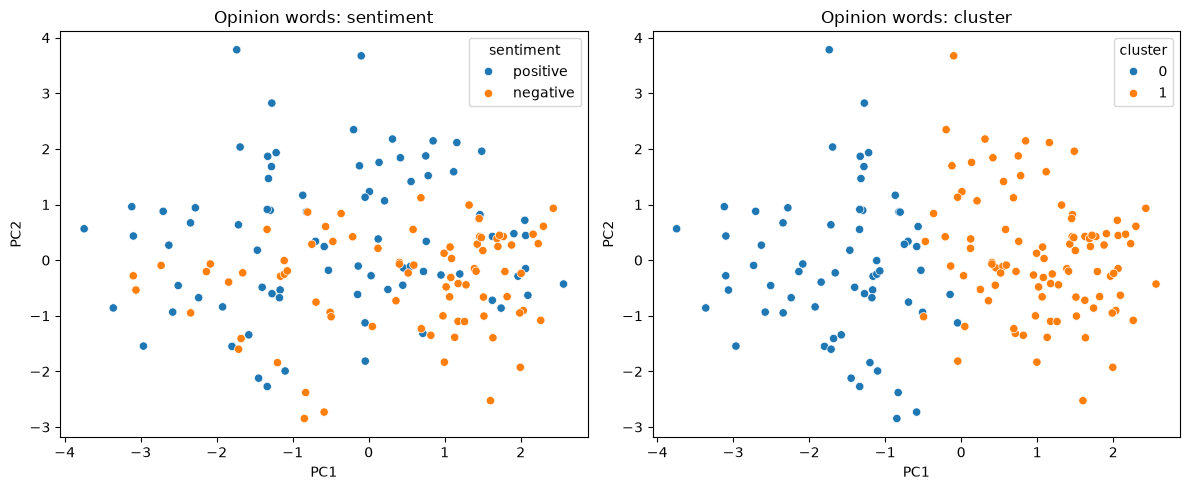

In [8]:
emb = embeddings[300]
pos = sorted({w for w in nltk.corpus.opinion_lexicon.positive() if w in emb})
neg = sorted({w for w in nltk.corpus.opinion_lexicon.negative() if w in emb}-set(pos))
rng = np.random.default_rng(BASE['sampling_seed'])
positive = rng.choice(pos, min(80, len(pos)), replace=False).tolist()
negative = rng.choice(neg, min(80, len(neg)), replace=False).tolist()
words = positive + negative
vectors = np.stack([emb.embed_word(w) for w in words])
clusters = KMeans(n_clusters=2, random_state=0, n_init=10).fit_predict(vectors)
points = PCA(n_components=2, random_state=0).fit_transform(vectors)
projection = pd.DataFrame({'word': words, 'PC1': points[:,0], 'PC2': points[:,1],
    'cluster': clusters, 'sentiment': ['positive']*len(positive)+['negative']*len(negative)})
save_result('lexical_projection', projection)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column in zip(axes, ['sentiment', 'cluster']):
    sns.scatterplot(data=projection, x='PC1', y='PC2', hue=column, ax=ax)
    ax.set_title(f'Opinion words: {column}')
fig.tight_layout()
save_figure(fig, 'lexical_pca_kmeans')
plt.show()

### Sentence similarity

Test **entailment > contradiction > neutral** similarity to the premise.
Average same-label hypotheses within each premise and retain groups containing
all three labels. Empty tokenized sentences receive UNK. Save pair scores and
the proportion of complete groups satisfying the proposed ordering.

,Ordering holds,Groups
dim,,
100,20.50%,"16,106"
300,20.24%,"16,106"


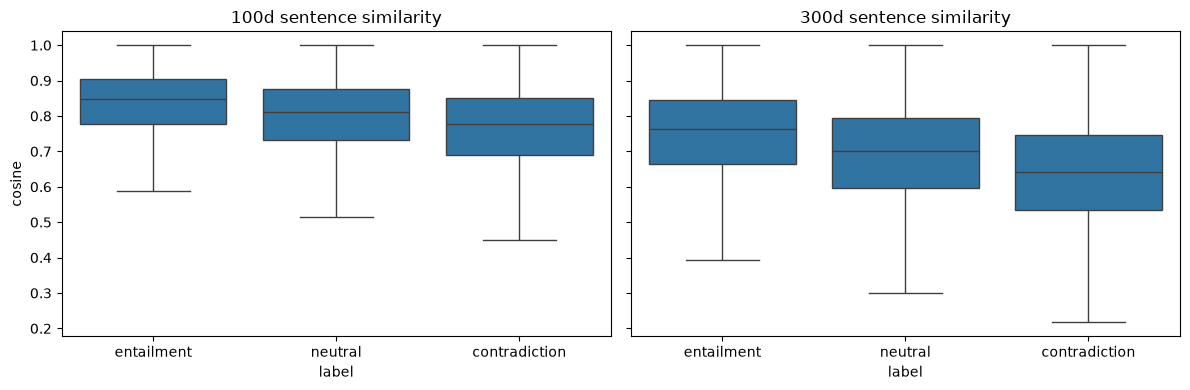

In [9]:
def encode_pairs(tokenized, emb):
    roles = [[np.asarray([emb.index(w) for w in sentence] or [emb.vocab.default_index], dtype=np.int64)
              for sentence in tokenized[role]] for role in ['premise', 'hypothesis']]
    return list(zip(*roles))


def pooled_pairs(pairs, emb):
    return np.stack([np.concatenate([emb.vectors[p].mean(0), emb.vectors[h].mean(0)])
                     for p, h in pairs]).astype(np.float32)


encoded = {(split, mode, dim): encode_pairs(ts, emb)
           for (split, mode), ts in tokens.items() for dim, emb in embeddings.items()}
pooled_train = {dim: pooled_pairs(encoded['train', 'pool', dim], emb) for dim, emb in embeddings.items()}
similarities = []
for dim, x in pooled_train.items():
    p, h = x[:, :dim], x[:, dim:]
    f = train[['example_id', 'premise', 'label']].copy()
    f['cosine'] = np.sum(p*h, axis=1)/np.maximum(np.linalg.norm(p, axis=1)*np.linalg.norm(h, axis=1), 1e-12)
    f['dim'] = dim
    similarities.append(f)
similarities = pd.concat(similarities, ignore_index=True)
groups = similarities.groupby(['dim', 'premise', 'label']).cosine.mean().unstack('label').dropna(subset=[0,1,2])
groups['proposed_order'] = (groups[0] > groups[2]) & (groups[2] > groups[1])
save_result('sentence_similarity', {'pairs': similarities, 'groups': groups})
display(groups.groupby('dim').proposed_order.agg(['mean', 'count'])
        .rename(columns={'mean': 'Ordering holds', 'count': 'Groups'})
        .style.format({'Ordering holds': '{:.2%}', 'Groups': '{:,.0f}'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, dim in zip(axes, BASE['embedding_dims']):
    sns.boxplot(data=similarities.loc[similarities.dim.eq(dim)], x='label', y='cosine', showfliers=False, ax=ax)
    ax.set(xticks=range(3), xticklabels=LABELS, title=f'{dim}d sentence similarity')
fig.tight_layout()
save_figure(fig, 'sentence_similarity')
plt.show()

## 5. Models and training

Use the course pool and packed LSTM encoders with a shared pair loader.
Right-pad premise and hypothesis separately, without truncation. All GloVe
weights remain frozen; LogReg, MLP1 and MLP2 have zero, one and two hidden layers.

The LSTM has two recurrent layers and an MLP2 head, with word masking and
classifier dropout. Additional layers do not themselves prevent overfitting;
inspect the training curves. Empty sentences receive UNK before packing.

In [10]:
class PairDataset(Dataset):
    def __init__(self, pairs, labels, indices):
        self.pairs, self.labels, self.indices = pairs, np.asarray(labels), np.asarray(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        i = self.indices[item]
        p, h = self.pairs[i]
        return torch.as_tensor(p), torch.as_tensor(h), int(self.labels[i])


def collate_pairs(rows):
    p, h, y = zip(*rows)
    return (pad_sequence(p, batch_first=True, padding_value=0),
            pad_sequence(h, batch_first=True, padding_value=0), torch.tensor(y, dtype=torch.long))


def make_loader(pairs, labels, indices=None, shuffle=False, seed=0):
    indices = np.arange(len(labels)) if indices is None else indices
    return DataLoader(PairDataset(pairs, labels, indices), batch_size=BASE['batch_size'],
        shuffle=shuffle, collate_fn=collate_pairs, generator=torch.Generator().manual_seed(seed))


class PairClassifier(nn.Module):
    def __init__(self, config, emb):
        super().__init__()
        matrix = torch.from_numpy(emb.vectors)
        if config['encoder'] == 'pool':
            self.encoder = clslib.EmbedAndPoolEncoder(matrix, freeze_embeddings=True)
        else:
            self.encoder = clslib.LSTMEncoder(config['hidden'], matrix,
                freeze_embeddings=True, word_dropout=config['dropout'])
            self.encoder.lstm = nn.LSTM(emb.num_dims, config['hidden'], num_layers=2, batch_first=True)
        width = 2*self.encoder.enc_dim
        layers = []
        for hidden in BASE['hidden_dims'][config['head']]:
            layers.extend([nn.Dropout(config['dropout']), nn.Linear(width, hidden), nn.Tanh()])
            width = hidden
        layers.extend([nn.Dropout(config['dropout']), nn.Linear(width, 3), nn.LogSoftmax(dim=-1)])
        self.output = nn.Sequential(*layers)

    def forward(self, premise, hypothesis):
        return self.output(torch.cat([self.encoder(premise), self.encoder(hypothesis)], dim=-1))

### Training loop

Use LogSoftmax, NLLLoss and AdamW; clip gradient norms at 5. Record accuracy,
NLL and macro-F1, using evaluation mode for held-out predictions. Training
curves are online minibatch measurements with dropout active.

CV scores the final epoch. Dev tuning alone restores the lowest-dev-NLL
checkpoint from epoch 5 through the pilot-selected budget. Save frozen GloVe separately from fitted weights.

In [11]:
def score(labels, probabilities):
    labels = np.asarray(labels)
    assert probabilities.shape == (len(labels), 3) and np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(1), 1, atol=1e-5)
    decisions = probabilities.argmax(1)
    return {'accuracy': accuracy_score(labels, decisions),
            'nll': -np.log(np.clip(probabilities[np.arange(len(labels)), labels], 1e-12, 1)).mean(),
            'macro_f1': f1_score(labels, decisions, labels=[0,1,2], average='macro', zero_division=0)}


def predict(model, loader):
    model.eval()
    probabilities, gold = [], []
    with torch.no_grad():
        for p, h, y in loader:
            probabilities.append(model(p.to(DEVICE), h.to(DEVICE)).exp().cpu().numpy())
            gold.append(y.numpy())
    return np.concatenate(probabilities), np.concatenate(gold)


def model_weights(model):
    # Keep frozen GloVe separately instead of duplicating it in every fit file.
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            if k != 'encoder.embedding.weight'}


def fit_model(config, training_loader, validation_loader=None, epochs=5, seed=0, select_epoch=False):
    set_seed(seed)
    model = PairClassifier(config, embeddings[config['dim']]).to(DEVICE)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
        lr=config['learning_rate'], weight_decay=BASE['weight_decay'])
    history, best_state, best_loss, selected_epoch = [], None, np.inf, epochs
    for epoch in range(1, epochs+1):
        model.train()
        total_loss, correct, count = 0., 0, 0
        for p, h, y in training_loader:
            y = y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logprobs = model(p.to(DEVICE), h.to(DEVICE))
            loss = nn.functional.nll_loss(logprobs, y)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.)
            if not torch.isfinite(gradient_norm):
                raise FloatingPointError('Nonfinite gradient norm')
            optimizer.step()
            total_loss += float(loss.detach())*len(y)
            correct += int((logprobs.argmax(1) == y).sum())
            count += len(y)
        row = {'epoch': epoch, 'train_nll': total_loss/count, 'train_accuracy': correct/count}
        if validation_loader is not None:
            probabilities, gold = predict(model, validation_loader)
            row.update({f'val_{k}': v for k, v in score(gold, probabilities).items()})
            if select_epoch and epoch >= BASE['min_epochs'] and row['val_nll'] < best_loss:
                best_loss, selected_epoch = row['val_nll'], epoch
                best_state = model_weights(model)
        history.append(row)
    if select_epoch:
        if best_state is None:
            raise ValueError('Epoch selection needs validation data and at least min_epochs.')
        model.load_state_dict(best_state, strict=False)
    return model.eval(), pd.DataFrame(history), selected_epoch

### Epoch pilot

Split groups inside fold 0's training portion. Fit 300d pooled MLP2 and LSTM
for up to 10 epochs, without using the scored fold or official dev. Choose
the larger minimum-validation-NLL epoch, clamped to 5–10, as the shared CV and
dev-search budget. Inspect train/validation curves for overfitting.

Only these two pilot fits use the 10-epoch ceiling directly. Later trials use
the pilot-selected budget; final refits use their selected dev checkpoint epoch.

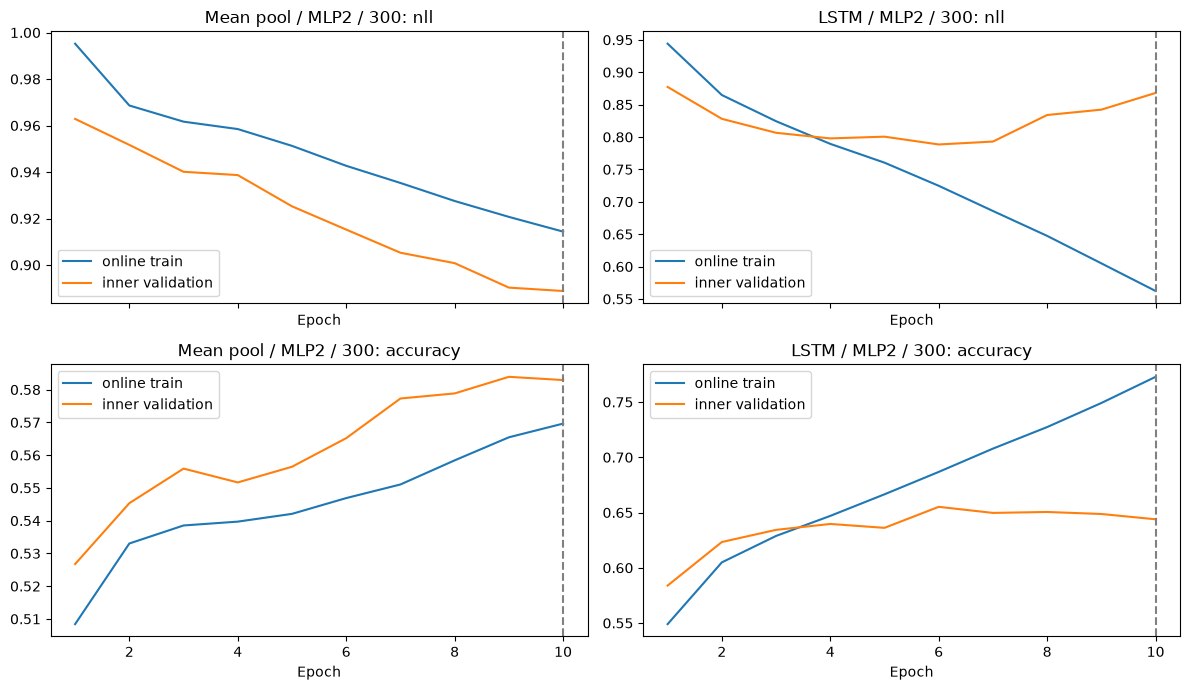

Pilot-selected training budget: 10


In [12]:
CANDIDATES = {}
for encoder, heads in [('pool', ['logreg', 'mlp1', 'mlp2']), ('lstm', ['mlp2'])]:
    for head, dim in product(heads, BASE['embedding_dims']):
        CANDIDATES[f'{encoder}-{head}-{dim}'] = {
            'encoder': encoder, 'head': head, 'dim': dim, 'hidden': BASE['lstm_hidden'],
            'dropout': BASE['dropout'], 'learning_rate': BASE['learning_rate']}

MODEL_NAMES = {name: name.replace('pool-', 'Mean pool / ').replace('lstm-', 'LSTM / ')
    .replace('logreg', 'LogReg').replace('mlp1', 'MLP1').replace('mlp2', 'MLP2')
    .replace('-', ' / ') for name in CANDIDATES}

outer_train = np.flatnonzero(assignments.seed_0.to_numpy() != 0)
splitter = GroupShuffleSplit(n_splits=1, test_size=.15, random_state=BASE['sampling_seed'])
a, b = next(splitter.split(outer_train, groups=train.iloc[outer_train].premise))
pilot_train, pilot_val = outer_train[a], outer_train[b]
pilot_histories = {}
for name in ['pool-mlp2-300', 'lstm-mlp2-300']:
    config = CANDIDATES[name]
    pairs = encoded['train', config['encoder'], config['dim']]
    training_loader = make_loader(pairs, train.label, pilot_train, shuffle=True)
    validation_loader = make_loader(pairs, train.label, pilot_val)
    model, history, _ = fit_model(config, training_loader, validation_loader, epochs=BASE['max_epochs'])
    pilot_histories[name] = history
    del model
TRAIN_EPOCHS = max(BASE['min_epochs'], max(int(h.loc[h.val_nll.idxmin(), 'epoch'])
                                      for h in pilot_histories.values()))
save_result('epoch_pilot', {'histories': pilot_histories, 'epochs': TRAIN_EPOCHS,
    'fit_ids': train.iloc[pilot_train].example_id.tolist(), 'validation_ids': train.iloc[pilot_val].example_id.tolist()})
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for column, (name, history) in enumerate(pilot_histories.items()):
    for row, metric in enumerate(['nll', 'accuracy']):
        ax = axes[row, column]
        ax.plot(history.epoch, history[f'train_{metric}'], label='online train')
        ax.plot(history.epoch, history[f'val_{metric}'], label='inner validation')
        ax.axvline(TRAIN_EPOCHS, color='gray', linestyle='--')
        ax.set(title=f'{MODEL_NAMES[name]}: {metric}', xlabel='Epoch')
        ax.legend()
fig.tight_layout()
save_figure(fig, 'pilot_learning_curves')
plt.show()
print('Pilot-selected training budget:', TRAIN_EPOCHS)

## 6. Cross-validation

Run six pooled designs and two LSTM dimensions on five grouped folds for each
of two seeds: **8 × 5 × 2 = 80 fits**. Use the pilot-selected fixed epoch count
and save fold scores, probabilities, IDs, histories, timing and weights.
Keep paired rows and training seeds across candidates. Do not select
checkpoints on scored folds. These are two CV repetitions on one fixed sample.

In [13]:
cv_rows, oof_rows = [], []
for seed, fold in tqdm(list(product(BASE['cv_seeds'], range(BASE['n_splits']))), desc='CV seed/fold'):
    fitting = np.flatnonzero(assignments[f'seed_{seed}'].to_numpy() != fold)
    heldout = np.flatnonzero(assignments[f'seed_{seed}'].to_numpy() == fold)
    fit_seed = BASE['model_seed'] + seed
    for name, config in CANDIDATES.items():
        started = perf_counter()
        pairs = encoded['train', config['encoder'], config['dim']]
        training_loader = make_loader(pairs, train.label, fitting, shuffle=True, seed=fit_seed)
        validation_loader = make_loader(pairs, train.label, heldout)
        model, history, _ = fit_model(config, training_loader, validation_loader, TRAIN_EPOCHS, fit_seed)
        probabilities, gold = predict(model, validation_loader)
        result = {'model': name, 'encoder': config['encoder'], 'seed': seed, 'fold': fold,
                  **score(gold, probabilities), 'seconds': perf_counter()-started,
                  'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad)}
        cv_rows.append(result)
        predictions = train.iloc[heldout][['example_id', 'label']].copy()
        predictions['model'], predictions['seed'], predictions['fold'] = name, seed, fold
        predictions['prediction'] = probabilities.argmax(1)
        for k in range(3):
            predictions[f'p{k}'] = probabilities[:,k]
        oof_rows.append(predictions)
        save_result(f'cv/{name}_seed{seed}_fold{fold}', {
            'config': config, 'metrics': result, 'history': history, 'weights': model_weights(model),
            'fit_ids': train.iloc[fitting].example_id.tolist(), 'predictions': predictions})
        del model
cv_scores, oof = pd.DataFrame(cv_rows), pd.concat(oof_rows, ignore_index=True)
assert len(cv_scores) == len(CANDIDATES)*BASE['n_splits']*len(BASE['cv_seeds'])
assert not oof.duplicated(['model', 'seed', 'example_id']).any()
assert oof.groupby(['model', 'seed']).example_id.nunique().eq(len(train)).all()
save_result('cross_validation', {'scores': cv_scores, 'predictions': oof})

CV seed/fold:   0%|          | 0/10 [00:00<?, ?it/s]

### CV results

Rank by mean accuracy across both seeds, then lower NLL and model name. Select
the best pooled and recurrent design for dev tuning. Show fold SD and all ten
fold scores, coloured by seed. Folds are dependent, two repetitions give only
a limited seed check, and the selected maximum is not an unbiased estimate
of the selection procedure.

,model,encoder,accuracy,accuracy_sd,nll,macro_f1,seconds,trainable_parameters
0,LSTM / MLP2 / 100,lstm,65.66%,0.44%,0.8013,0.6559,876.4,"1,237,553"
1,LSTM / MLP2 / 300,lstm,65.45%,0.68%,0.8650,0.6540,873.1,"1,477,553"
7,Mean pool / MLP2 / 300,pool,59.14%,0.37%,0.8841,0.5906,264.8,"32,753"
5,Mean pool / MLP1 / 300,pool,59.06%,0.45%,0.8910,0.5898,245.8,"30,203"
3,Mean pool / LogReg / 300,pool,55.26%,0.52%,0.9443,0.5518,223.7,"1,803"
6,Mean pool / MLP2 / 100,pool,55.12%,0.40%,0.9407,0.5492,264.8,"12,753"
4,Mean pool / MLP1 / 100,pool,54.54%,0.38%,0.9511,0.5438,245.2,"10,203"
2,Mean pool / LogReg / 100,pool,52.76%,0.28%,0.9773,0.5267,224.2,603


Selected: Mean pool / MLP2 / 300, LSTM / MLP2 / 100


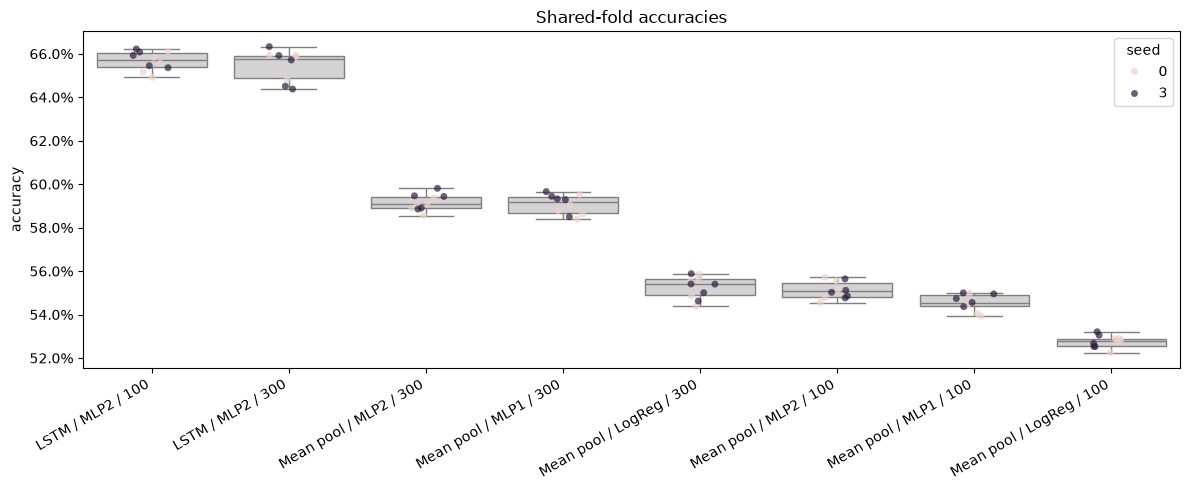

In [ ]:
summary = cv_scores.groupby(['model', 'encoder']).agg(
    accuracy=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'), nll=('nll', 'mean'),
    macro_f1=('macro_f1', 'mean'), seconds=('seconds', 'sum'),
    trainable_parameters=('trainable_parameters', 'mean')).reset_index()
summary = summary.sort_values(['accuracy', 'nll', 'model'], ascending=[False, True, True])
selected = {family: summary.loc[summary.encoder.eq(family)].iloc[0].model for family in ['pool', 'lstm']}
save_result('cv_selection', {'summary': summary, 'selected': selected, 'epochs': TRAIN_EPOCHS})
display(summary.replace({'model': MODEL_NAMES}).style.format({
    'accuracy': '{:.2%}', 'accuracy_sd': '{:.2%}', 'nll': '{:.4f}',
    'macro_f1': '{:.4f}', 'seconds': '{:.1f}', 'trainable_parameters': '{:,.0f}'}))
print('Selected:', ', '.join(MODEL_NAMES[name] for name in selected.values()))
fig, ax = plt.subplots(figsize=(12, 5))
order = summary.model.tolist()
sns.boxplot(data=cv_scores, x='model', y='accuracy', order=order, color='lightgray', showfliers=False, ax=ax)
sns.stripplot(data=cv_scores, x='model', y='accuracy', hue='seed', order=order, jitter=.15, alpha=.7, ax=ax)
ax.set_xticks(range(len(order)), [MODEL_NAMES[name] for name in order], rotation=30, ha='right')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Shared-fold accuracies', xlabel='')
fig.tight_layout()
save_figure(fig, 'cv_boxplots_and_points')
plt.show()

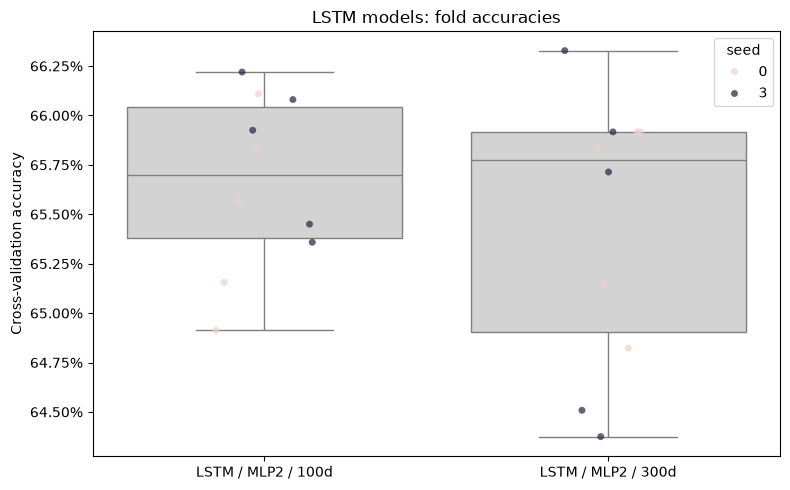

Loaded 20 LSTM CV fold results from: /scratch-shared/scur0565/project2/RESULTS/cross_validation.pkl


In [10]:
# Standalone: cross-validation boxplots for the LSTM models only.
import sys
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import seaborn as sns

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'part2/clslib.py').exists())
sys.path.insert(0, str(ROOT))

SCRATCH = Path('/scratch-shared/scur0565/project2/RESULTS')
cv_path = SCRATCH / 'cross_validation.pkl'
if not cv_path.exists():
    cv_path = ROOT / 'part2/project2_results/RESULTS_selected/cross_validation.pkl'
if not cv_path.exists():
    raise FileNotFoundError(f'Could not find cross_validation.pkl: {cv_path}')

with cv_path.open('rb') as handle:
    cv_scores = pickle.load(handle)['scores']

lstm_cv = cv_scores.loc[cv_scores['encoder'].eq('lstm')].copy()
order = ['lstm-mlp2-100', 'lstm-mlp2-300']
labels = ['LSTM / MLP2 / 100d', 'LSTM / MLP2 / 300d']

assert set(order).issubset(set(lstm_cv['model']))
assert len(lstm_cv) == 20

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=lstm_cv, x='model', y='accuracy', order=order,
            color='lightgray', showfliers=False, ax=ax)
sns.stripplot(data=lstm_cv, x='model', y='accuracy', hue='seed',
              order=order, jitter=.15, alpha=.7, ax=ax)

ax.set_xticks(range(len(order)), labels)
ax.set_xlabel('')
ax.set_ylabel('Cross-validation accuracy')
ax.set_title('LSTM models: fold accuracies')
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

print(f'Loaded {len(lstm_cv)} LSTM CV fold results from: {cv_path}')


### Bayesian comparisons and ROPE

Compare matched seed/fold scores with the correlated-t posterior for B−A:
scale = `sqrt((1/n + 1/(k−1)) × sample variance)`, with n−1 degrees of freedom.
The correction approximates the validation/training size ratio.

Compare dimensions within heads, heads within dimensions, and the selected
encoders. Use ROPE ±.5 percentage points, with ±.1 and ±1 point sensitivity.
Comparisons after CV selection remain exploratory.
The ten matched scores come from dependent folds in just two repetitions.
Small differences and posterior probabilities still need cautious interpretation.

,A,B,rope,mean,low95,high95,P_A,P_equal,P_B
1,Mean pool / LogReg / 100,Mean pool / LogReg / 300,0.5%,+2.50%,+1.88%,+3.13%,0.0%,0.0%,100.0%
4,Mean pool / MLP1 / 100,Mean pool / MLP1 / 300,0.5%,+4.52%,+3.81%,+5.23%,0.0%,0.0%,100.0%
7,Mean pool / MLP2 / 100,Mean pool / MLP2 / 300,0.5%,+4.03%,+3.32%,+4.74%,0.0%,0.0%,100.0%
10,Mean pool / LogReg / 100,Mean pool / MLP1 / 100,0.5%,+1.79%,+1.26%,+2.31%,0.0%,0.0%,100.0%
13,Mean pool / MLP1 / 100,Mean pool / MLP2 / 100,0.5%,+0.57%,+0.11%,+1.04%,0.0%,36.6%,63.4%
16,Mean pool / LogReg / 300,Mean pool / MLP1 / 300,0.5%,+3.80%,+3.07%,+4.53%,0.0%,0.0%,100.0%
19,Mean pool / MLP1 / 300,Mean pool / MLP2 / 300,0.5%,+0.08%,-0.53%,+0.69%,2.9%,89.2%,7.8%
22,LSTM / MLP2 / 100,LSTM / MLP2 / 300,0.5%,-0.21%,-0.94%,+0.52%,19.7%,77.5%,2.7%
25,Mean pool / MLP2 / 300,LSTM / MLP2 / 100,0.5%,+6.52%,+5.77%,+7.26%,0.0%,0.0%,100.0%


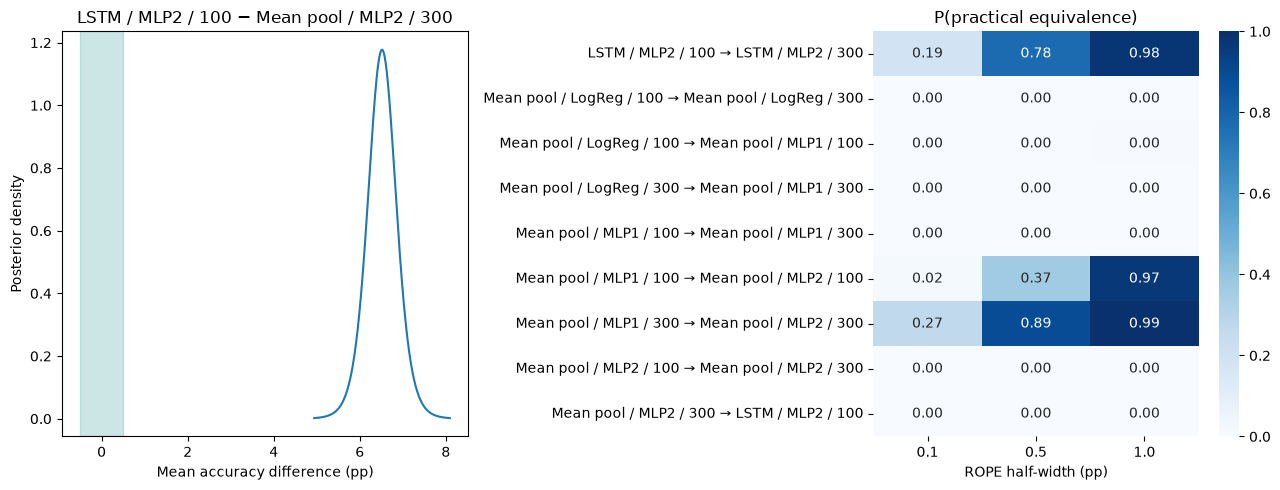

In [15]:
def correlated_posterior(a, b, rope=BASE['rope']):
    differences = np.asarray(b)-np.asarray(a)
    mean, n = float(differences.mean()), len(differences)
    scale = np.sqrt((1/n + 1/(BASE['n_splits']-1))*differences.var(ddof=1))
    if scale < 1e-12:
        return {'mean': mean, 'scale': scale, 'df': n-1, 'low95': mean, 'high95': mean,
                'P_A': float(mean < -rope), 'P_equal': float(abs(mean) <= rope), 'P_B': float(mean > rope)}
    posterior = t(n-1, loc=mean, scale=scale)
    low, high = posterior.interval(.95)
    return {'mean': mean, 'scale': scale, 'df': n-1, 'low95': low, 'high95': high,
            'P_A': posterior.cdf(-rope), 'P_equal': posterior.cdf(rope)-posterior.cdf(-rope), 'P_B': posterior.sf(rope)}


matched = cv_scores.pivot(index=['seed', 'fold'], columns='model', values='accuracy').sort_index()
assert not matched.isna().any().any()
comparisons = [(f'pool-{head}-100', f'pool-{head}-300') for head in ['logreg', 'mlp1', 'mlp2']]
comparisons += [(f'pool-{a}-{dim}', f'pool-{b}-{dim}') for dim in [100,300]
                for a,b in [('logreg','mlp1'), ('mlp1','mlp2')]]
comparisons += [('lstm-mlp2-100', 'lstm-mlp2-300'), (selected['pool'], selected['lstm'])]
posteriors = pd.DataFrame([{'A': a, 'B': b, 'rope': rope,
    **correlated_posterior(matched[a], matched[b], rope)}
    for a,b in comparisons for rope in [.001, .005, .01]])
save_result('cv_posteriors', posteriors)
display(posteriors.loc[posteriors.rope.eq(BASE['rope'])]
    .drop(columns=['scale', 'df']).replace({'A': MODEL_NAMES, 'B': MODEL_NAMES})
    .style.format({'rope': '{:.1%}', 'mean': '{:+.2%}', 'low95': '{:+.2%}',
                   'high95': '{:+.2%}', 'P_A': '{:.1%}', 'P_equal': '{:.1%}', 'P_B': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
a, b = selected['pool'], selected['lstm']
r = correlated_posterior(matched[a], matched[b])
if r['scale'] > 1e-12:
    distribution = t(r['df'], loc=r['mean'], scale=r['scale'])
    xs = np.linspace(*distribution.interval(.999), 500)
    axes[0].plot(xs*100, distribution.pdf(xs)/100)
else:
    axes[0].axvline(r['mean']*100)
axes[0].axvspan(-BASE['rope']*100, BASE['rope']*100, alpha=.2, color='teal')
axes[0].set(title=f'{MODEL_NAMES[b]} − {MODEL_NAMES[a]}', xlabel='Mean accuracy difference (pp)', ylabel='Posterior density')
sensitivity = posteriors.assign(comparison=posteriors.A.map(MODEL_NAMES)+' → '+posteriors.B.map(MODEL_NAMES), rope_pp=posteriors.rope*100)
sns.heatmap(sensitivity.pivot(index='comparison', columns='rope_pp', values='P_equal'),
            vmin=0, vmax=1, annot=True, fmt='.2f', cmap='Blues', ax=axes[1])
axes[1].set(title='P(practical equivalence)', xlabel='ROPE half-width (pp)', ylabel='')
fig.tight_layout()
save_figure(fig, 'posterior_and_rope_sensitivity')
plt.show()

## 7. Dev tuning

Keep the CV-selected heads and dimensions. Starting from the incumbent, vary
**one parameter at a time**: dropout .10/.15/.20, learning rate .1/.2/.3,
and LSTM hidden size 100/300/500. Hold other settings at their incumbent values
and skip duplicates. Including the .001 incumbent gives **6 pooled + 8 LSTM =
14 trials**. Word masking and classifier dropout share the dropout setting.

Use the same 60k training sample, seed 0 and official dev. Fit for the
pilot-selected budget, choosing minimum dev NLL from epoch 5 through that
limit. Rank checkpoints by dev accuracy, NLL and trial name. Save nonfinite
trials. Dev scores are optimistic selection scores. This smaller search does
not test interactions or combine separately promising changes.

In [ ]:
tuning_rows, tuned = {}, {}
for family in ['pool', 'lstm']:
    base = CANDIDATES[selected[family]]
    options = {'incumbent': dict(base)}
    search = {'dropout': BASE['tune_dropout'], 'learning_rate': BASE['tune_learning_rate']}
    if family == 'lstm':
        search['hidden'] = BASE['tune_hidden']
    for parameter, values in search.items():
        for value in values:
            if value != base[parameter]:
                options[f'{parameter}{value:g}'] = {**base, parameter: value}
    pairs = encoded['train', family, base['dim']]
    dev_pairs = encoded['dev', family, base['dim']]
    family_rows = []
    for trial, config in tqdm(options.items(), desc=f'Tuning {family}'):
        started = perf_counter()
        row = {'family': family, 'trial': trial, **config, 'status': 'ok'}
        try:
            training_loader = make_loader(pairs, train.label, shuffle=True, seed=BASE['model_seed'])
            validation_loader = make_loader(dev_pairs, dev.label)
            model, history, epoch = fit_model(config, training_loader, validation_loader,
                TRAIN_EPOCHS, BASE['model_seed'], select_epoch=True)
            probabilities, gold = predict(model, validation_loader)
            row.update(score(gold, probabilities), epochs=epoch, seconds=perf_counter()-started)
            save_result(f'tuning/{family}_{trial}', {'config': config, 'history': history,
                'probabilities': probabilities, 'epochs': epoch, 'weights': model_weights(model),
                'fit_ids': train.example_id.tolist(), 'validation_ids': dev.example_id.tolist()})
            del model
        except FloatingPointError as error:
            row.update(status='nonfinite', error=str(error))
            save_result(f'tuning/{family}_{trial}', row)
        family_rows.append(row)
    table = pd.DataFrame(family_rows)
    successful = table.loc[table.status.eq('ok')].sort_values(['accuracy','nll','trial'], ascending=[False,True,True])
    if successful.empty:
        raise RuntimeError(f'No finite trials for {family}; inspect the saved results.')
    winner = successful.iloc[0]
    tuned[family] = {'config': options[winner.trial], 'epochs': int(winner.epochs), 'trial': winner.trial}
    tuning_rows.extend(family_rows)
tuning_scores = pd.DataFrame(tuning_rows)
save_result('dev_tuning', {'scores': tuning_scores, 'selected': tuned})
display(tuning_scores[['family','dropout','learning_rate','hidden','epochs','accuracy','nll','status']]
    .sort_values(['family','accuracy'], ascending=[True,False]).style.format(
        {'dropout': '{:.2f}', 'learning_rate': '{:.3f}', 'epochs': '{:.0f}',
         'accuracy': '{:.2%}', 'nll': '{:.4f}'}, na_rep='—'))
print('Selected settings:')
display(pd.DataFrame([dict(choice['config'], epochs=choice['epochs']) for choice in tuned.values()]))

Tuning pool:   0%|          | 0/6 [00:00<?, ?it/s]

Tuning lstm:   0%|          | 0/8 [00:00<?, ?it/s]

,family,dropout,learning_rate,hidden,epochs,accuracy,nll,status
6,lstm,0.10,0.001,300,6,66.76%,0.7533,ok
13,lstm,0.10,0.001,500,6,66.75%,0.7490,ok
7,lstm,0.15,0.001,300,8,66.23%,0.7592,ok
12,lstm,0.10,0.001,100,9,66.17%,0.7669,ok
8,lstm,0.20,0.001,300,9,66.16%,0.7713,ok
9,lstm,0.10,0.100,300,6,33.31%,1.1014,ok
10,lstm,0.10,0.200,300,5,32.87%,1.1529,ok
11,lstm,0.10,0.300,300,5,32.87%,1.2744,ok
0,pool,0.10,0.001,300,10,61.31%,0.8555,ok
1,pool,0.15,0.001,300,10,60.45%,0.8722,ok


Selected settings:


,encoder,head,dim,hidden,dropout,learning_rate,epochs
0,pool,mlp2,300,300,0.1,0.001,10
1,lstm,mlp2,100,300,0.1,0.001,6


### Dev results and curves

Plot the individual dev trials, which vary one parameter at a time. Reload the
selected trial histories and show train/dev NLL with the chosen epoch.
Inspect overfitting without changing decisions from test results.

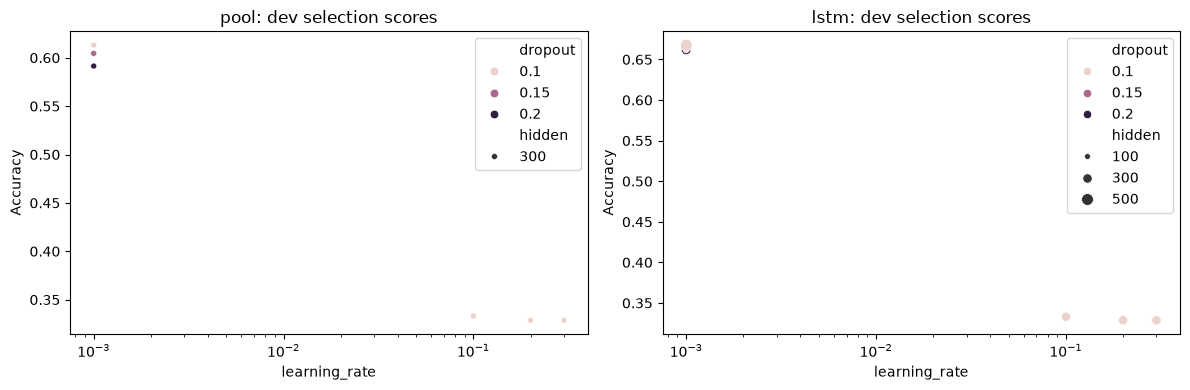

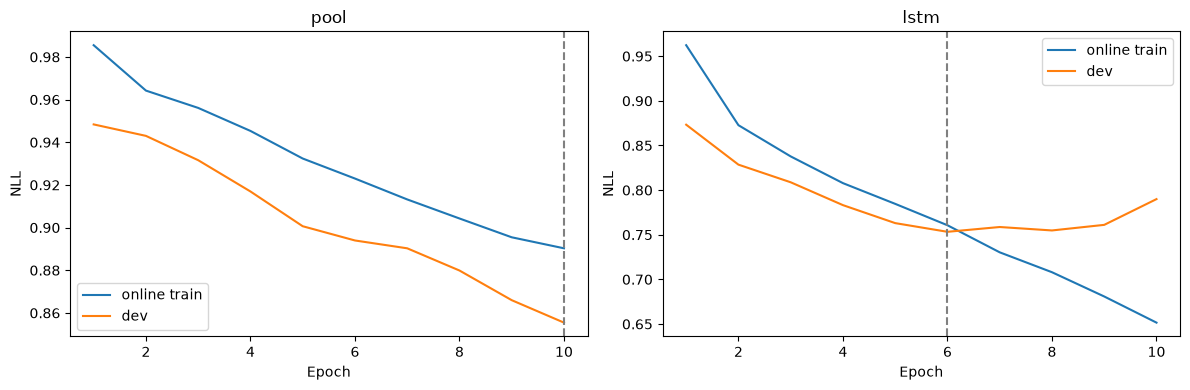

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, family in zip(axes, ['pool', 'lstm']):
    subset = tuning_scores.loc[tuning_scores.family.eq(family) & tuning_scores.status.eq('ok')]
    sns.scatterplot(data=subset, x='learning_rate', y='accuracy', hue='dropout', size='hidden', ax=ax)
    ax.set(xscale='log', title=f'{family}: dev selection scores', ylabel='Accuracy')
fig.tight_layout()
save_figure(fig, 'dev_search')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, family in zip(axes, ['pool', 'lstm']):
    with (RESULTS / f"tuning/{family}_{tuned[family]['trial']}.pkl").open('rb') as handle:
        history = pickle.load(handle)['history']
    ax.plot(history.epoch, history.train_nll, label='online train')
    ax.plot(history.epoch, history.val_nll, label='dev')
    ax.axvline(tuned[family]['epochs'], color='gray', linestyle='--')
    ax.set(title=family, xlabel='Epoch', ylabel='NLL')
    ax.legend()
fig.tight_layout()
save_figure(fig, 'selected_dev_curves')
plt.show()

## 8. Final refit and test

Freeze settings, epochs and seed. Refit both winners on the same fixed training
sample without adding dev, and save weights before test prediction.
Report accuracy, NLL, macro-F1 and test vocabulary coverage.

The earlier reported 74.48% test accuracy is historical context: its training
size and selection procedure differ. This test set has been used before.

In [18]:
final_models, final_histories = {}, {}
for family, choice in tuned.items():
    config = choice['config']
    training_loader = make_loader(encoded['train', family, config['dim']], train.label,
                                  shuffle=True, seed=BASE['model_seed'])
    model, history, _ = fit_model(config, training_loader, epochs=choice['epochs'], seed=BASE['model_seed'])
    save_result(f'final_{family}', {'config': config, 'epochs': choice['epochs'],
        'seed': BASE['model_seed'], 'weights': model_weights(model), 'history': history,
        'fit_ids': train.example_id.tolist()})
    final_models[family], final_histories[family] = model.cpu(), history

# All choices above are fixed before constructing test inputs or predictions.
test_tokens = {mode: tokenize_pairs(test, mode) for mode in TOKENIZERS}
test_probabilities = {}
for family, choice in tuned.items():
    config = choice['config']
    pairs = encode_pairs(test_tokens[family], embeddings[config['dim']])
    model = final_models[family].to(DEVICE)
    test_probabilities[family], gold = predict(model, make_loader(pairs, test.label))
    assert np.array_equal(gold, test.label.to_numpy())
    model.cpu()
save_result('test_predictions', {'probabilities': test_probabilities, 'example_ids': test.example_id.tolist(),
    'labels': test.label.to_numpy(), 'choices': tuned})
test_scores = pd.DataFrame([{'model': family, **score(test.label, p)} for family,p in test_probabilities.items()])
save_result('test_scores', test_scores)
display(test_scores.replace({'model': {'pool': 'Mean pool', 'lstm': 'LSTM'}})
    .style.format({'accuracy': '{:.2%}', 'nll': '{:.4f}', 'macro_f1': '{:.4f}'}))
test_coverage = pd.DataFrame(list(chain.from_iterable(
    coverage_table('test', mode, ts, emb) for mode,ts in test_tokens.items() for emb in embeddings.values())))
save_result('test_coverage', test_coverage)
display(test_coverage.drop(columns='top_oov').style.format(
    {'token_coverage': '{:.2%}', 'type_coverage': '{:.2%}'}))

,model,accuracy,nll,macro_f1
0,Mean pool,61.56%,0.8532,0.6155
1,LSTM,67.39%,0.7535,0.6719


,split,mode,role,dim,tokens,types,oov_tokens,oov_types,token_coverage,type_coverage,empty_sentences
0,test,pool,premise,100,78289,3957,106,35,99.86%,99.12%,0
1,test,pool,hypothesis,100,39803,4994,155,141,99.61%,97.18%,0
2,test,pool,premise,300,78289,3957,106,35,99.86%,99.12%,0
3,test,pool,hypothesis,300,39803,4994,155,141,99.61%,97.18%,0
4,test,lstm,premise,100,148880,4160,411,118,99.72%,97.16%,0
5,test,lstm,hypothesis,100,81704,5158,186,163,99.77%,96.84%,0
6,test,lstm,premise,300,148880,4160,411,118,99.72%,97.16%,0
7,test,lstm,hypothesis,300,81704,5158,186,163,99.77%,96.84%,0


### Class performance

Show precision, recall, F1 and support for each label. Confusion-matrix rows
are normalized by the true label; off-diagonal cells show class confusions.
Save the full reports.

pool


,precision,recall,f1-score,support
entailment,0.618,0.643,0.630,"3,368"
neutral,0.581,0.625,0.602,"3,219"
contradiction,0.654,0.579,0.614,"3,237"


lstm


,precision,recall,f1-score,support
entailment,0.660,0.762,0.707,"3,368"
neutral,0.680,0.640,0.660,"3,219"
contradiction,0.686,0.615,0.649,"3,237"


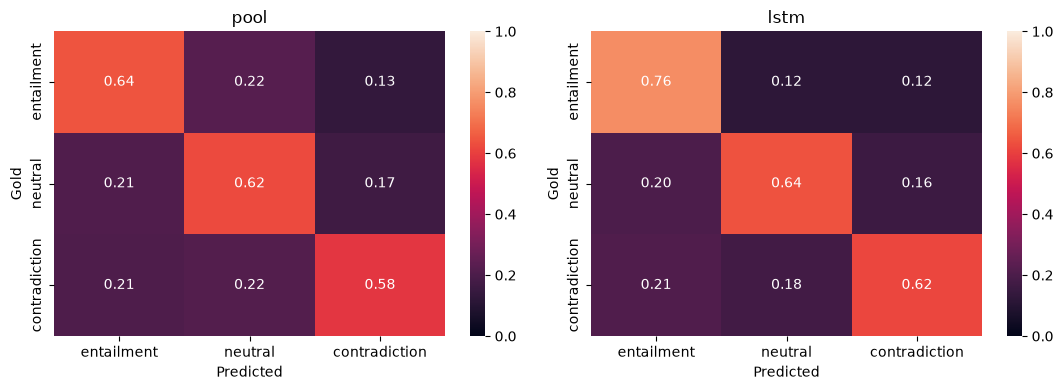

In [19]:
reports = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (family, probabilities) in zip(axes, test_probabilities.items()):
    prediction = probabilities.argmax(1)
    reports[family] = classification_report(test.label, prediction, labels=[0,1,2],
        target_names=LABELS, output_dict=True, zero_division=0)
    print(family)
    display(pd.DataFrame(reports[family]).T.loc[LABELS].style.format(
        {'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:,.0f}'}))
    matrix = confusion_matrix(test.label, prediction, labels=[0,1,2], normalize='true')
    sns.heatmap(matrix, annot=True, fmt='.2f', vmin=0, vmax=1,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(title=family, xlabel='Predicted', ylabel='Gold')
fig.tight_layout()
save_figure(fig, 'test_confusion_matrices')
plt.show()
save_result('classification_reports', reports)

## 9. Error analysis

Sample about 1,200 whole-group test pairs for both final systems. Measure length,
negation, negation mismatch, overlap and OOV rate. Define a semantic sibling as
a training hypothesis with 300d pooled cosine ≥ .9; fix the threshold beforehand.

Search in blocks and save nearest-example IDs and labels. Hidden size and
dimension are model metadata, constant within a system. This test analysis
describes errors and does not retune the models.

In [20]:
def nearest_hypotheses(queries, references, query_batch=128, reference_batch=8192):
    if len(references) == 0:
        raise ValueError('Sibling search needs training references.')
    queries = queries/np.maximum(np.linalg.norm(queries, axis=1, keepdims=True), 1e-12)
    references = references/np.maximum(np.linalg.norm(references, axis=1, keepdims=True), 1e-12)
    best, nearest = np.full(len(queries), -np.inf), np.full(len(queries), -1, dtype=int)
    for start in range(0, len(queries), query_batch):
        stop = min(start+query_batch, len(queries))
        for rs in range(0, len(references), reference_batch):
            scores = queries[start:stop] @ references[rs:rs+reference_batch].T
            indices = scores.argmax(1)
            values = scores[np.arange(stop-start), indices]
            improve = values > best[start:stop]
            best[start:stop][improve] = values[improve]
            nearest[start:stop][improve] = (rs+indices)[improve]
    return best, nearest


sample = sample_groups(test, min(BASE['analysis_rows'], len(test)), BASE['sampling_seed'])
positions = pd.Series(np.arange(len(test)), index=test.example_id).loc[sample.example_id].to_numpy()
sample_tokens = {role: [test_tokens['pool'][role][i] for i in positions] for role in ['premise','hypothesis']}
query_vectors = pooled_pairs(encode_pairs(sample_tokens, embeddings[300]), embeddings[300])[:,300:]
max_cosine, nearest = nearest_hypotheses(query_vectors, pooled_train[300][:,300:])
NEGATION = {'no','not',"n't",'never','nothing','nobody','none','neither','nor','without'}
feature_rows = []
for j, i in enumerate(positions):
    p, h = (test_tokens['lstm'][role][i] for role in ['premise','hypothesis'])
    ps, hs = set(p), set(h)
    pn, hn = bool(ps & NEGATION), bool(hs & NEGATION)
    feature_rows.append({'example_id': test.iloc[i].example_id,
        'premise_length': len(p), 'hypothesis_length': len(h),
        'has_negation': int(pn or hn), 'negation_mismatch': int(pn != hn),
        'lexical_overlap': len(ps & hs)/max(1, len(ps | hs)),
        'oov_rate': sum(w not in embeddings[300] for w in p+h)/max(1, len(p)+len(h)),
        'sibling_cosine': max_cosine[j], 'has_sibling': int(max_cosine[j] >= BASE['sibling_threshold']),
        'nearest_training_id': train.iloc[nearest[j]].example_id,
        'nearest_training_label': int(train.iloc[nearest[j]].label)})
features = pd.DataFrame(feature_rows)
error_rows = []
for system_id, (family, probabilities) in enumerate(test_probabilities.items()):
    f = features.copy()
    f['system'], f['system_id'] = family, system_id
    f['label'], f['prediction'] = test.iloc[positions].label.to_numpy(), probabilities[positions].argmax(1)
    f['correct'] = f.prediction.eq(f.label).astype(int)
    f['embedding_dim'], f['hidden_units'] = tuned[family]['config']['dim'], tuned[family]['config']['hidden'] if family == 'lstm' else 0
    error_rows.append(f)
errors = pd.concat(error_rows, ignore_index=True)
save_result('error_features', errors)
display(errors.groupby('system').agg(accuracy=('correct','mean'), rows=('correct','size'), sibling_rate=('has_sibling','mean')))

,accuracy,rows,sibling_rate
system,,,
lstm,0.673877,1202,0.43178
pool,0.597338,1202,0.43178


### Mistakes and feature slices

Inspect example mistakes with their nearest training neighbour. Compare accuracy
with and without negation, mismatch and a sibling, showing each slice's count.
Small slices can be unstable; the first displayed errors are illustrative.

,system,premise,hypothesis,label,prediction,sibling_cosine,nearest_training_id,nearest_training_label
3,pool,A blond-haired doctor and her African american...,A doctor is looking at a book,0,1,0.859331,train:425727,2
5,pool,A blond-haired doctor and her African american...,A doctor is studying,1,2,0.802903,train:387380,1
7,pool,A snowboarder on a wide plain of snow,A snowboarder gliding over a field of snow,1,2,0.759190,train:69367,2
8,pool,A snowboarder on a wide plain of snow,A snowmobile in a blizzard,1,2,0.549059,train:224697,2
10,pool,A man in a black shirt overlooking bike mainte...,A man watches bike repairs.,0,1,0.809869,train:27968,2
13,pool,A child wearing a red top is standing behind a...,A child wearing a red top is standing on top o...,2,0,0.883333,train:493755,0
14,pool,A child wearing a red top is standing behind a...,A child wearing a red top is standing behind a...,1,0,0.857042,train:335796,1
18,pool,People are conversing at a dining table under ...,People at a party are seated for dinner on the...,1,2,0.850517,train:28710,2
19,pool,People are conversing at a dining table under ...,People are talking underneath a covering.,0,2,0.838640,train:366689,0
27,pool,A person in a red shirt and black pants hunche...,The person is a woman.,1,0,1.000000,train:329923,1


,system,has_negation,mean,count
0,lstm,0,67.21%,"1,171"
1,lstm,1,74.19%,31
2,pool,0,60.03%,"1,171"
3,pool,1,48.39%,31


,system,negation_mismatch,mean,count
0,lstm,0,67.15%,"1,172"
1,lstm,1,76.67%,30
2,pool,0,59.98%,"1,172"
3,pool,1,50.00%,30


,system,has_sibling,mean,count
0,lstm,0,63.25%,683
1,lstm,1,72.83%,519
2,pool,0,56.66%,683
3,pool,1,63.78%,519


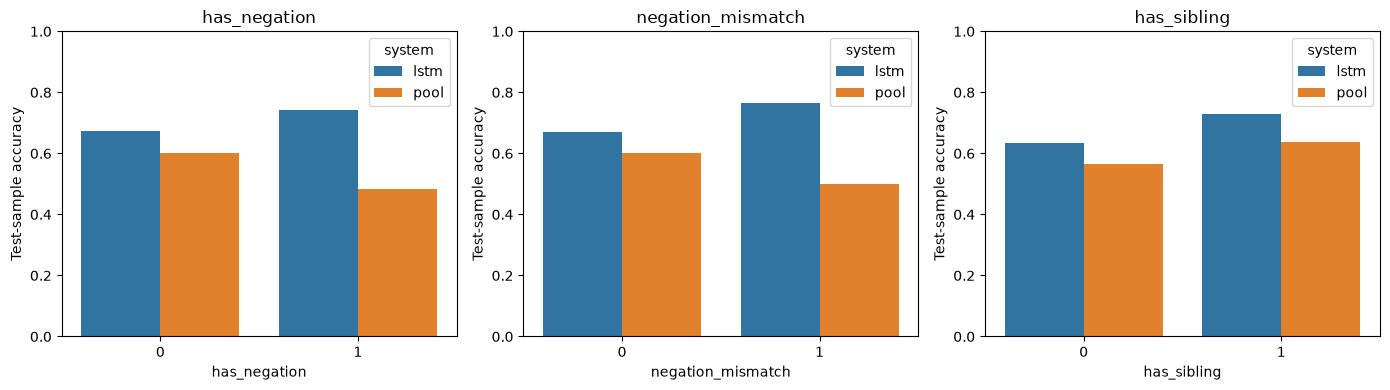

In [21]:
qualitative = errors.merge(test[['example_id','premise','hypothesis']], on='example_id', validate='many_to_one')
display(qualitative.loc[qualitative.correct.eq(0), ['system','premise','hypothesis','label','prediction',
    'sibling_cosine','nearest_training_id','nearest_training_label']].head(20))
save_result('qualitative_errors', qualitative)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, ['has_negation','negation_mismatch','has_sibling']):
    slices = errors.groupby(['system',feature]).correct.agg(['mean','count']).reset_index()
    display(slices.style.format({'mean': '{:.2%}', 'count': '{:,.0f}'}))
    sns.barplot(data=slices, x=feature, y='mean', hue='system', ax=ax)
    ax.set(title=feature, ylabel='Test-sample accuracy', ylim=(0,1))
fig.tight_layout()
save_figure(fig, 'error_slices')
plt.show()

### Bayesian error analysis

Use the tutorial's correctness regression with system shifts, input-feature
slopes and predicted-class indicators (entailment is the reference). Drop
constant columns and standardize through the course helper. Save the scaling,
samples and diagnostics; inspect R-hat, ESS and divergences before interpretation.

These are associations, not causes. Predicted class describes model output.
The likelihood omits shared item/premise effects, so intervals may be optimistic.
Keep hidden size and embedding dimension as metadata because they are fixed
within each system. CV/ROPE provides the main design comparison.

In [22]:
import arviz as az

numeric = ['premise_length','hypothesis_length','has_negation','negation_mismatch',
           'lexical_overlap','oov_rate','has_sibling']
label_features = pd.DataFrame({f'pred:{LABELS[k]}': errors.prediction.eq(k).astype(float) for k in [1,2]})
x = pd.concat([errors[numeric].astype(float), label_features], axis=1)
dropped = x.columns[x.std(ddof=0) < 1e-12].tolist()
x = x.drop(columns=dropped)
assert np.isfinite(x.to_numpy()).all()
mcmc = analysis.fit_bda_model(num_systems=2, sys_id=errors.system_id.to_numpy(),
    features=x.to_numpy(), correctness=errors.correct.to_numpy(), seed=BASE['model_seed'],
    num_warmup=BASE['mcmc_warmup'], num_samples=BASE['mcmc_samples'], num_chains=BASE['mcmc_chains'])
posterior = analysis.posterior_to_arviz(mcmc, ['pool','lstm'], x.columns.tolist())
diagnostics = az.summary(posterior, var_names=['global_mean','sys_shift','w'], kind='diagnostics')
divergences = int(np.asarray(mcmc.get_extra_fields()['diverging']).sum())
save_result('bda', {'posterior': posterior, 'diagnostics': diagnostics, 'divergences': divergences,
    'samples': {k: np.asarray(v) for k,v in mcmc.get_samples(group_by_chain=True).items()},
    'feature_names': x.columns.tolist(), 'dropped': dropped, 'feature_mean': x.mean().to_dict(),
    'feature_scale': np.sqrt(x.var(ddof=0)+1e-5).to_dict()})
display(diagnostics)
print('Divergences:', divergences)
if divergences or (diagnostics.r_hat > 1.01).any() or (diagnostics.ess_bulk < 400).any():
    print('Inspect convergence before interpreting the posterior intervals.')

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.



  0%|          | 0/2000 [00:00<?, ?it/s]


warmup:   5%|▌         | 100/2000 [00:01<00:34, 54.40it/s, 31 steps of size 2.80e-02. acc. prob=0.87]


warmup:  10%|█         | 200/2000 [00:03<00:27, 64.60it/s, 63 steps of size 6.62e-02. acc. prob=0.88]


warmup:  15%|█▌        | 300/2000 [00:04<00:22, 75.68it/s, 63 steps of size 2.82e-02. acc. prob=0.88]


warmup:  20%|██        | 400/2000 [00:05<00:18, 87.02it/s, 63 steps of size 7.47e-02. acc. prob=0.88]

... (37 outputs left out)


sample: 100%|██████████| 2000/2000 [00:15<00:00, 130.79it/s, 63 steps of size 5.22e-02. acc. prob=0.93]


sample: 100%|██████████| 2000/2000 [00:15<00:00, 125.87it/s, 63 steps of size 5.22e-02. acc. prob=0.93]

,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
global_mean,668,609,1.00,0.028,0.03
sys_shift[pool],664,620,1.00,0.028,0.03
sys_shift[lstm],670,636,1.00,0.028,0.03
"w[pool, premise_length]",2094,1463,1.00,0.0013,0.0013
"w[pool, hypothesis_length]",1722,1372,1.00,0.0016,0.0015
"w[pool, has_negation]",907,581,1.00,0.024,0.035
"w[pool, negation_mismatch]",883,593,1.00,0.023,0.034
"w[pool, lexical_overlap]",1889,1627,1.00,0.0015,0.0013
"w[pool, oov_rate]",1876,1353,1.00,0.0015,0.0016
"w[pool, has_sibling]",1881,1408,1.00,0.0015,0.0013


Divergences: 0


### Posterior plots

Show system shifts, model-based accuracy and standardized feature weights.
Points are medians; intervals contain 50% and 95% posterior mass. Positive
weights indicate higher conditional correctness. Check convergence first;
model-based accuracy is distinct from measured test accuracy.

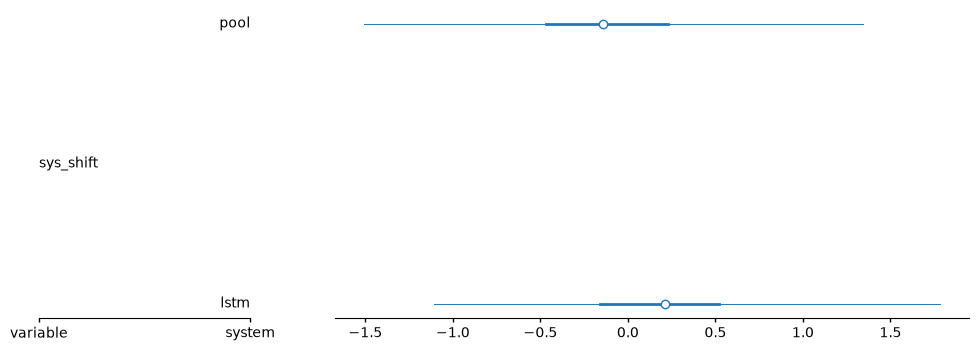

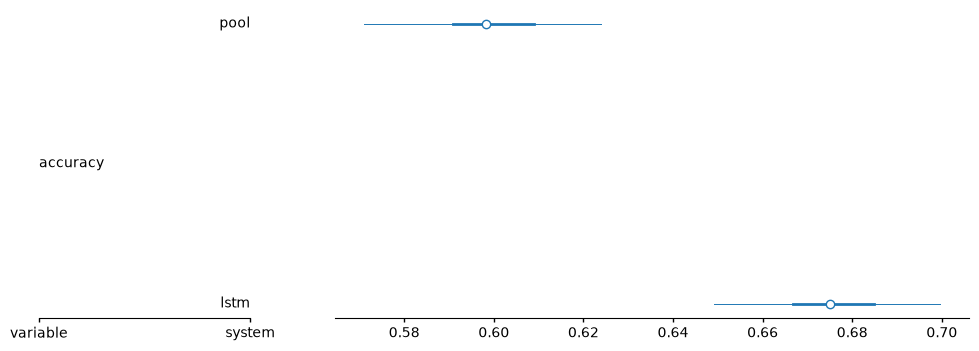

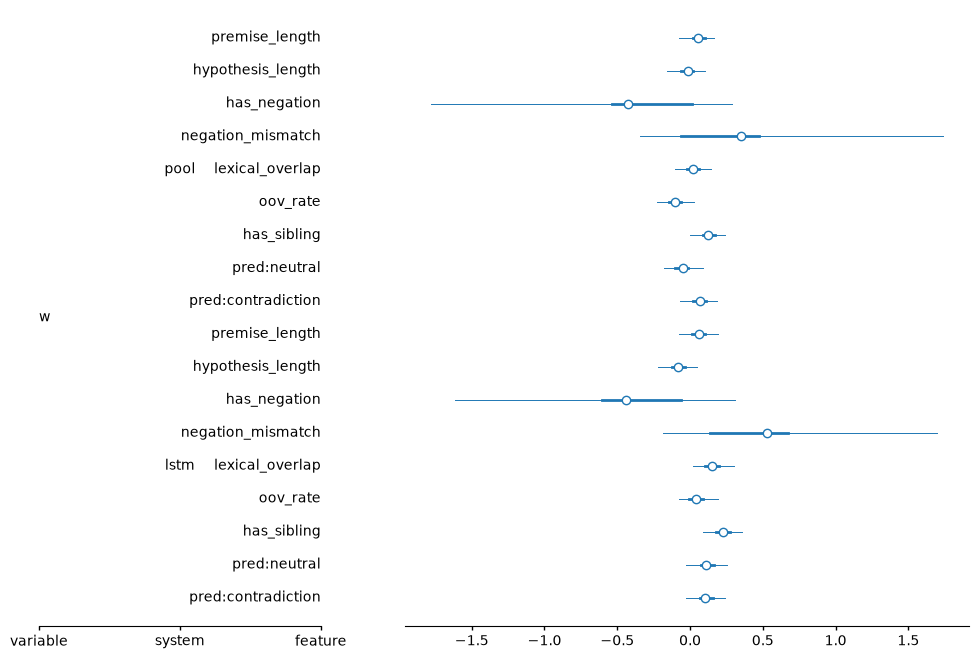

In [23]:
# Forest-plot interface used in the tutorial (ArviZ 1.x).
for variable in ['sys_shift','accuracy','w']:
    plot = az.plot_forest(posterior, var_names=[variable], combined=True,
        ci_kind='hdi', ci_probs=(.5,.95), point_estimate='median', backend='matplotlib',
        figure_kwargs={'figsize': (12, 8 if variable == 'w' else 4)})
    for extension in ['png','pdf']:
        plot.savefig(FIGURES / f'bda_{variable}.{extension}', dpi=180, bbox_inches='tight')
    plt.show()

In [5]:
import sys, pickle
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

ROOT = '/home/scur0565/nlp1-student-gp57'
sys.path.insert(0, ROOT)
from part2 import clslib

SCRATCH = Path('/scratch-shared/scur0565/project2/RESULTS')
SELECTED = Path(ROOT) / 'part2/project2_results/RESULTS_selected'
THRESH = 0.95

with open(SELECTED / 'qualitative_errors.pkl', 'rb') as f:
    df = pickle.load(f)
with open(SCRATCH / 'train_dev_tokens.pkl', 'rb') as f:
    train_premises = pickle.load(f)['train', 'pool']['premise']
with open(SCRATCH / 'glove_300.pkl', 'rb') as f:
    emb = pickle.load(f)

tokenizer = clslib.BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True)

def pooled(token_lists):
    return np.stack([emb.vectors[[emb.index(w) for w in s] or [emb.vocab.default_index]].mean(0)
                     for s in token_lists]).astype(np.float32)

def unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)

# training premises (each appears in several pairs, so deduplicate)
unique_train = list({tuple(s): s for s in train_premises}.values())
train_vectors = unit(pooled(unique_train))

# nearest training premise for each distinct test premise
test_premises = df['premise'].drop_duplicates().tolist()
test_vectors = unit(pooled([tokenizer.tokens(t) for t in test_premises]))
premise_cosine = pd.Series((test_vectors @ train_vectors.T).max(1), index=test_premises)

df = df.copy()
df['premise_cosine'] = df['premise'].map(premise_cosine)
df['premise_sibling'] = (df['premise_cosine'] >= THRESH).astype(int)
df['hypothesis_sibling'] = (df['sibling_cosine'] >= THRESH).astype(int)

print(f'Test premises with a training premise at cosine >= {THRESH}: '
      f'{(premise_cosine >= THRESH).mean():.1%} of {len(premise_cosine)} premises')

# 1) accuracy with and without a premise sibling
summary = (df.groupby(['system', 'premise_sibling'])
             .agg(premises=('premise', 'nunique'), rows=('correct', 'size'), accuracy=('correct', 'mean'))
             .reset_index())
display(summary.style.hide(axis='index').format({'accuracy': '{:.4f}'}))

# 2) the same, split by whether the hypothesis also has a sibling at this threshold
two_by_two = (df.groupby(['system', 'hypothesis_sibling', 'premise_sibling'])
                .agg(rows=('correct', 'size'), accuracy=('correct', 'mean')).reset_index())
display(two_by_two.style.hide(axis='index').format({'accuracy': '{:.4f}'}))

# 3) accuracy difference (with minus without premise sibling), bootstrapped over premises
rng = np.random.default_rng(0)

def boot_diff(d, n_boot=5000):
    per = d.groupby('premise').agg(n=('correct', 'size'), c=('correct', 'sum'), flag=('premise_sibling', 'first'))
    yes, no = per[per.flag.eq(1)], per[per.flag.eq(0)]
    if len(yes) == 0 or len(no) == 0:
        return np.nan, np.nan, np.nan
    yn, yc, nn, nc = (yes.n.to_numpy(), yes.c.to_numpy(), no.n.to_numpy(), no.c.to_numpy())
    observed = yc.sum()/yn.sum() - nc.sum()/nn.sum()
    ia = rng.integers(0, len(yn), (n_boot, len(yn)))
    ib = rng.integers(0, len(nn), (n_boot, len(nn)))
    diffs = yc[ia].sum(1)/yn[ia].sum(1) - nc[ib].sum(1)/nn[ib].sum(1)
    return observed, *np.percentile(diffs, [2.5, 97.5])

result = pd.DataFrame([dict(system=s, **dict(zip(['difference', 'ci_low', 'ci_high'], boot_diff(d))))
                       for s, d in df.groupby('system')])
display(result.style.hide(axis='index').format({c: '{:+.2%}' for c in ['difference', 'ci_low', 'ci_high']}))

Test premises with a training premise at cosine >= 0.95: 1.2% of 409 premises


system,premise_sibling,premises,rows,accuracy
lstm,0,404,1187,0.6748
lstm,1,5,15,0.6000
pool,0,404,1187,0.5956
pool,1,5,15,0.7333


system,hypothesis_sibling,premise_sibling,rows,accuracy
lstm,0,0,933,0.6549
lstm,0,1,11,0.6364
lstm,1,0,254,0.7480
lstm,1,1,4,0.5000
pool,0,0,933,0.5766
pool,0,1,11,0.7273
pool,1,0,254,0.6654
pool,1,1,4,0.7500


system,difference,ci_low,ci_high
lstm,-7.48%,-28.17%,+14.25%
pool,+13.77%,+5.02%,+27.68%


In [ ]:
import sys, pickle
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

ROOT = '/home/scur0565/nlp1-student-gp57'
sys.path.insert(0, ROOT)
from part2 import clslib

THRESHOLDS = [0.90, 0.95, 0.97]   # edit this list to try other cutoffs
SCRATCH = Path('/scratch-shared/scur0565/project2/RESULTS')
SELECTED = Path(ROOT) / 'part2/project2_results/RESULTS_selected'

with open(SELECTED / 'qualitative_errors.pkl', 'rb') as f:
    df = pickle.load(f)
with open(SCRATCH / 'train_dev_tokens.pkl', 'rb') as f:
    train_premises = pickle.load(f)['train', 'pool']['premise']
with open(SCRATCH / 'glove_300.pkl', 'rb') as f:
    emb = pickle.load(f)

tokenizer = clslib.BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True)

def pooled(token_lists):
    return np.stack([emb.vectors[[emb.index(w) for w in s] or [emb.vocab.default_index]].mean(0)
                     for s in token_lists]).astype(np.float32)

def unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)



# training premises (each appears in several pairs, so deduplicate)
unique_train = list({tuple(s): s for s in train_premises}.values())
train_vectors = unit(pooled(unique_train))

# nearest training premise for each distinct test premise (computed once)
test_premises = df['premise'].drop_duplicates().tolist()
test_vectors = unit(pooled([tokenizer.tokens(t) for t in test_premises]))
premise_cosine = pd.Series((test_vectors @ train_vectors.T).max(1), index=test_premises)
df = df.copy()
df['premise_cosine'] = df['premise'].map(premise_cosine)

def analyse(d, n_boot=5000):
    """Accuracy with vs without a premise sibling; bootstrap over premises."""
    rng = np.random.default_rng(0)
    per = d.groupby('premise').agg(n=('correct', 'size'), c=('correct', 'sum'), flag=('premise_sibling', 'first'))
    yes, no = per[per.flag.eq(1)], per[per.flag.eq(0)]
    out = {'premises_with': len(yes), 'premises_without': len(no),
           'acc_with': yes.c.sum() / yes.n.sum() if len(yes) else np.nan,
           'acc_without': no.c.sum() / no.n.sum() if len(no) else np.nan,
           'difference': np.nan, 'ci_low': np.nan, 'ci_high': np.nan}
    if len(yes) and len(no):
        yn, yc, nn, nc = yes.n.to_numpy(), yes.c.to_numpy(), no.n.to_numpy(), no.c.to_numpy()
        ia = rng.integers(0, len(yn), (n_boot, len(yn)))
        ib = rng.integers(0, len(nn), (n_boot, len(nn)))
        diffs = yc[ia].sum(1) / yn[ia].sum(1) - nc[ib].sum(1) / nn[ib].sum(1)
        out['difference'] = out['acc_with'] - out['acc_without']
        out['ci_low'], out['ci_high'] = np.percentile(diffs, [2.5, 97.5])
    return out

rows, two_by_two = [], {}
for thr in THRESHOLDS:
    d_thr = df.assign(premise_sibling=(df['premise_cosine'] >= thr).astype(int),
                      hypothesis_sibling=(df['sibling_cosine'] >= thr).astype(int))
    for system, d in d_thr.groupby('system'):
        rows.append({'threshold': thr, 'system': system, **analyse(d)})
    two_by_two[thr] = (d_thr.groupby(['system', 'hypothesis_sibling', 'premise_sibling'])
                            .agg(rows=('correct', 'size'), accuracy=('correct', 'mean')).reset_index())

results = pd.DataFrame(rows)
results['share_with_sibling'] = results.premises_with / (results.premises_with + results.premises_without)
columns = ['threshold', 'system', 'share_with_sibling', 'premises_with', 'premises_without',
           'acc_with', 'acc_without', 'difference', 'ci_low', 'ci_high']

print('Accuracy with vs without a premise sibling, by threshold')
display(results[columns].style.hide(axis='index').format({
    'threshold': '{:.2f}', 'share_with_sibling': '{:.1%}',
    'acc_with': '{:.2%}', 'acc_without': '{:.2%}',
    'difference': '{:+.2%}', 'ci_low': '{:+.2%}', 'ci_high': '{:+.2%}'}, na_rep='—'))

for thr, table in two_by_two.items():
    print(f'Hypothesis sibling x premise sibling at cosine >= {thr:.2f}')
    display(table.style.hide(axis='index').format({'accuracy': '{:.2%}'}))

Accuracy with vs without a premise sibling, by threshold


threshold,system,share_with_sibling,premises_with,premises_without,acc_with,acc_without,difference,ci_low,ci_high
0.90,lstm,17.1%,70,339,65.09%,67.88%,-2.78%,-9.91%,+3.99%
0.90,pool,17.1%,70,339,60.85%,59.49%,+1.35%,-5.87%,+8.41%
0.95,lstm,1.2%,5,404,60.00%,67.48%,-7.48%,-28.17%,+14.25%
0.95,pool,1.2%,5,404,73.33%,59.56%,+13.77%,+5.05%,+27.77%
0.97,lstm,0.2%,1,408,100.00%,67.31%,+32.69%,+30.14%,+35.30%
0.97,pool,0.2%,1,408,100.00%,59.63%,+40.37%,+37.66%,+43.19%


Hypothesis sibling x premise sibling at cosine >= 0.90


system,hypothesis_sibling,premise_sibling,rows,accuracy
lstm,0,0,611,64.48%
lstm,0,1,72,52.78%
lstm,1,0,379,73.35%
lstm,1,1,140,71.43%
pool,0,0,611,56.79%
pool,0,1,72,55.56%
pool,1,0,379,63.85%
pool,1,1,140,63.57%


Hypothesis sibling x premise sibling at cosine >= 0.95


system,hypothesis_sibling,premise_sibling,rows,accuracy
lstm,0,0,933,65.49%
lstm,0,1,11,63.64%
lstm,1,0,254,74.80%
lstm,1,1,4,50.00%
pool,0,0,933,57.66%
pool,0,1,11,72.73%
pool,1,0,254,66.54%
pool,1,1,4,75.00%


Hypothesis sibling x premise sibling at cosine >= 0.97


system,hypothesis_sibling,premise_sibling,rows,accuracy
lstm,0,0,998,65.73%
lstm,0,1,2,100.00%
lstm,1,0,201,75.12%
lstm,1,1,1,100.00%
pool,0,0,998,58.12%
pool,0,1,2,100.00%
pool,1,0,201,67.16%
pool,1,1,1,100.00%


## 10. Discussion and saved results

After execution, discuss coverage, lexical relations, sentence similarity,
dimension, architecture, overfitting and error patterns. Read differences with
their uncertainty. Static polysemy, corpus bias and selection optimism remain
limitations; pretraining itself has not been isolated with an ablation.
Training-size and trainable-embedding experiments remain future work.
Two repetitions give a limited seed check; the smaller dev search omits interactions.

Run cells in order using root `requirements.txt`, including NumPyro/JAX and the
tutorial's ArviZ 1.x interface. There are 2 pilots, 80 CV fits, 14 dev trials
and 2 final refits: **98 planned fits**. Heavy stages remain unrun. Run All retrains and overwrites
same-named pickle files. Load saved results directly for post-processing;
embedding files can be large.

Sources: [design notes](project2.md), [tutorial](tutorial.ipynb), course
[encoders](../clslib.py) and [Bayesian helpers](../analysis.py).
Implementation used AI assistance; conclusions await execution.

In [24]:
# Example: reload saved measurements without retraining.
with (RESULTS / 'cross_validation.pkl').open('rb') as handle:
    saved_cv = pickle.load(handle)
display(saved_cv['scores'].head())
print('Results:', RESULTS)
print('Figures:', FIGURES)

,model,encoder,seed,fold,accuracy,nll,macro_f1,seconds,trainable_parameters
0,pool-logreg-100,pool,0,0,0.529000,0.978516,0.526932,22.329936,603
1,pool-logreg-300,pool,0,0,0.543833,0.947190,0.541762,22.315660,1803
2,pool-mlp1-100,pool,0,0,0.549667,0.950319,0.545768,24.523990,10203
3,pool-mlp1-300,pool,0,0,0.586333,0.893707,0.584759,24.448931,30203
4,pool-mlp2-100,pool,0,0,0.557167,0.932653,0.552941,26.589654,12753


Results: /scratch-shared/scur0565/project2/RESULTS
Figures: /scratch-shared/scur0565/project2/figures


In [3]:
# Reload saved lexical probes and embeddings without rerunning the experiment.
from pathlib import Path
import pickle
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'part2/clslib.py').exists())
sys.path.insert(0, str(root))
from part2 import clslib

workspace_results = root / 'part2/project2_results/RESULTS_selected'
scratch_results = Path('/scratch-shared/scur0565/project2/RESULTS')

probe_path = scratch_results / 'lexical_probes.pkl'
if not probe_path.exists():
    probe_path = workspace_results / 'lexical_probes.pkl'

with probe_path.open('rb') as handle:
    probes = pickle.load(handle)

embeddings = {}
for dim in (100, 300):
    path = scratch_results / f'glove_{dim}.pkl'
    if path.exists():
        with path.open('rb') as handle:
            embeddings[dim] = pickle.load(handle)

print('Probe source:', probe_path)
print('Loaded probe tables:', ', '.join(probes))
print('Loaded embeddings:', sorted(embeddings))
for name, table in probes.items():
    display(table.round(3).style.hide(axis='index'))

ModuleNotFoundError: No module named 'numpy'